# Probe registration direction workbench
Temporary analysis/development notebook. Remove after reviewed results are transferred to the appropriate code and figures.

Recreates the SimNIRS Figure 1 registration view for **pain** and **pattern cutting**, and the pain current-versus-legacy comparison from `visualize_registered_probes.py`. All source and detector arrows are large, equal-length glyphs in **RAS mm**, pointing as stored/computed (never flipped for appearance). Multiple cameras expose projection and far-side overlap.

Baseline first: retained prepared archives and the exact SimNIRS figure inputs, followed by fresh registration using this checkout. Candidate direction methods change **only directions at fixed positions**. No production code or input archive is changed, and no transport/Jacobians are run. Export is off by default.

Questions: Are directions locally inward? How much of the apparent disorder is camera overlap, stale vectors, or a small mesh neighborhood? Does a broader connected patch improve stability without making vectors leave the head? Smooth appearance alone is not evidence of correctness.

In [28]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.io import loadmat
from scipy.spatial import cKDTree
from IPython.display import display, Markdown, HTML

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "mmcnirs/light_transport/register_probe.py").is_file())
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from mmcnirs.light_transport.register_probe import register_probe
from mmcnirs.utils.mesh_utils import make_surface_mesh, as_element_array, _find_containing_elements
from mmcnirs.utils.probe_utils import (find_smoothed_surface_directions, find_center_directions,
                                     load_channel_pairs_from_snirf, normalize_channel_pairings)
import trimesh

SIMNIRS = ROOT.parent / "simnirs"
FIGURE_NOTEBOOK = SIMNIRS / "review_experiments/overview_figure/figure1_anatomy_sensitivity.ipynb"
ARROW_LENGTH_MM = 30.0
ARROW_WIDTH_PT = 1.8
LABEL_OPTODES = False
CAMERAS = {"oblique": (24, -68), "left profile": (0, 180), "frontal": (0, 90), "superior": (90, -90)}
EXPORT = False
EXPORT_DIR = ROOT / "notebooks/probe_registration_direction_workbench_outputs"
COLORS = {"source": "#c53b50", "detector": "#0077b6", "mesh": "#ccd1d5"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": False})
def load_npz(path):
    with np.load(path, allow_pickle=False) as z:
        return {k: z[k].copy() for k in z.files}
def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def table(rows):
    keys = list(rows[0])
    display(Markdown("| " + " | ".join(keys) + " |\n|" + "|".join(["---"] * len(keys)) + "|\n" +
                     "\n".join("| " + " | ".join(str(r[k]) for k in keys) + " |" for r in rows)))
def save_figure(fig, name):
    if EXPORT:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EXPORT_DIR / (name + ".png"), dpi=170, bbox_inches="tight")
print("Repository:", ROOT)
print("Python:", sys.executable)
print("Arrows:", ARROW_LENGTH_MM, "mm (display glyphs, not propagation paths)")

Repository: /Users/nielsbracher/Projects/mmc-nirs
Python: /Users/nielsbracher/Projects/mmc-nirs/.venv/bin/python
Arrows: 30.0 mm (display glyphs, not propagation paths)


## 1. Input audit
The active retained workflows use `legacy/*/mmcnirs_outputs/{mesh,probe}.npz`. The legacy comparison scripts still name root-level `mesh.npz/current_probe.npz` and import the retired `mmc_nirs` package; they are references, not executable entry points here.

Pain raw probe: `probe.SD → SD.SrcPos/DetPos`, LIA mm. Pattern cutting: `probe.mat → sourcepos/detpos`, RAS mm. Each uses its own prepared mesh. Indexing is explicit: prepared meshes/pairings are zero-based; SNIRF pairings are normalized by the repository loader. The input mesh archives are inventoried without replacing prepared geometry.

SimNIRS Figure 1 reads `dev_experiments/hardware-pain/{mesh,probe}.npz`; it displays stored vectors, not a fresh registration. Its renderer deliberately overlays all far-side optodes. The original 28 mm arrows are reproduced here at the configurable 30 mm diagnostic length with source/detector colors.

In [29]:
datasets = {}
provenance = []
for name, folder, raw_name, snirf_name in [
    ("pain", "pain_data", "probe.SD", "FingerTapping.snirf"),
    ("pattern cutting", "pattern_cutting_data", "probe.mat", "NIRS-2019-08-10_006.snirf"),
]:
    directory = ROOT / "legacy" / folder
    config = json.loads((directory / "config.json").read_text())
    mesh_path = directory / config["filepaths"]["meshfile"]
    probe_path = directory / config["filepaths"]["probefile"]
    mesh, stored = load_npz(mesh_path), load_npz(probe_path)
    nodes = mesh["nodes"][:, :3]
    # Canonical prepared mesh: explicit zero-based, do not infer from minimum.
    elements = as_element_array(mesh["elements"], len(nodes), index_base="zero")
    raw = loadmat(directory / raw_name, squeeze_me=True, struct_as_record=False)
    if name == "pain":
        raw_sources, raw_detectors = raw["SD"].SrcPos, raw["SD"].DetPos
    else:
        raw_sources, raw_detectors = raw["sourcepos"], raw["detpos"]
    pairings = load_channel_pairs_from_snirf(directory / snirf_name)
    pairings = normalize_channel_pairings(pairings, len(raw_sources), len(raw_detectors))
    surface = make_surface_mesh(nodes, elements)
    datasets[name] = dict(directory=directory, config=config, nodes=nodes, elements=elements,
                          surface=surface, stored=stored, raw_sources=np.asarray(raw_sources, float),
                          raw_detectors=np.asarray(raw_detectors, float), pairings=pairings)
    with np.load(directory / "input_mesh.npz", allow_pickle=False) as z:
        input_summary = ", ".join(f"{k}:{z[k].shape}" for k in z.files)
    print(name, "| input_mesh:", input_summary)
    print(" prepared mesh keys:", list(mesh), "| probe keys:", list(stored))
    for path in [directory / "config.json", directory / raw_name, directory / snirf_name, mesh_path, probe_path]:
        provenance.append(dict(dataset=name, path=str(path.relative_to(ROOT)), sha256=sha256(path)))
    print(f" {len(nodes):,} nodes; {len(elements):,} tetrahedra; {len(surface.faces):,} exterior triangles")
    print(" raw/stored counts:", len(raw_sources), len(raw_detectors), "| channels:", len(pairings))
    print(" settings:", config["probe_settings"])
    assert stored["sourcepos"].shape == np.asarray(raw_sources).shape
    assert stored["detpos"].shape == np.asarray(raw_detectors).shape

figure_inputs = {}
for name in ("mesh", "probe"):
    path = SIMNIRS / "dev_experiments/hardware-pain" / f"{name}.npz"
    if path.is_file():
        figure_inputs[name] = load_npz(path)
        provenance.append(dict(dataset="SimNIRS Figure 1", path=str(path), sha256=sha256(path)))
if figure_inputs:
    fm, fp = figure_inputs["mesh"], figure_inputs["probe"]
    print("SimNIRS mesh keys:", list(fm), "| probe keys:", list(fp))
    for key in ("sourcepos", "detpos", "sourcedir", "detnorms"):
        a, b = fp[key], datasets["pain"]["stored"][key]
        print(f" Figure 1 vs retained pain {key}: max absolute difference = {np.max(np.abs(a-b)):.6g}")
table([dict(dataset=k, orientation=v["config"]["probe_settings"]["probe_orientation"],
            units=v["config"]["probe_settings"]["probe_units"],
            sources=len(v["raw_sources"]), detectors=len(v["raw_detectors"]))
       for k,v in datasets.items()])
table(provenance)

pain | input_mesh: elem:(330983, 5), face:(242958, 4), nodes:(58686, 4)
 prepared mesh keys: ['nodes', 'elements', 'node_tissue_ids', 'element_tissue_ids', 'ordered_tissue_ids', 'ordered_tissues'] | probe keys: ['sourcepos', 'detpos', 'sourcedir', 'detnorms', 'source_elements', 'detector_elements', 'channel_pairings', 'short_separation_indices', 'long_separation_indices']
 58,686 nodes; 330,983 tetrahedra; 21,698 exterior triangles
 raw/stored counts: 15 31 | channels: 51
 settings: {'probe_orientation': 'LIA', 'probe_units': 'mm', 'embedding_step': 0.5, 'short_separation_flag': 'distance', 'short_separation_arg': 20.0, 'max_embedding_steps': 1000}
pattern cutting | input_mesh: elem:(330983, 5), face:(242958, 4), nodes:(58686, 4)
 prepared mesh keys: ['nodes', 'elements', 'node_tissue_ids', 'element_tissue_ids', 'ordered_tissue_ids', 'ordered_tissues'] | probe keys: ['sourcepos', 'detpos', 'sourcedir', 'detnorms', 'source_elements', 'detector_elements', 'channel_pairings', 'short_separ

| dataset | orientation | units | sources | detectors |
|---|---|---|---|---|
| pain | LIA | mm | 15 | 31 |
| pattern cutting | RAS | mm | 8 | 27 |

| dataset | path | sha256 |
|---|---|---|
| pain | legacy/pain_data/config.json | 987784081f6ea135ab3002304823d4e77fdd061eb2c699bd0027bf50e0912ba8 |
| pain | legacy/pain_data/probe.SD | f1d54d226670cedd753d962207d2bf1eb7d31d69b2f3a31804b6ac72478b6f9e |
| pain | legacy/pain_data/FingerTapping.snirf | bfd5306c5f8fc9f76ce400fcc3017279f35bf0c75ac49499cbf17295b1b7df91 |
| pain | legacy/pain_data/mmcnirs_outputs/mesh.npz | 4488eae7b2333b9a3bef4886990dd6a35b58f0917ad1f9975f23feda1442a8cd |
| pain | legacy/pain_data/mmcnirs_outputs/probe.npz | c42968dfc9fb250e4cff8de211ed3d3d41fe074550b48873dd9759b2b00cef98 |
| pattern cutting | legacy/pattern_cutting_data/config.json | b3eb7a3ed5a8412e0a0cfc0d885ee69cc8d8c94c2490f367956cdeb29ed96853 |
| pattern cutting | legacy/pattern_cutting_data/probe.mat | dffa54dc9892e51de36edcda03ba4e8c6e973d2700cf6663bbe2c2501d06c409 |
| pattern cutting | legacy/pattern_cutting_data/NIRS-2019-08-10_006.snirf | 793f3d63eb2da7a20b859ba481f7d683e491f50fc4658f948c229462df8d5f65 |
| pattern cutting | legacy/pattern_cutting_data/mmcnirs_outputs/mesh.npz | 4488eae7b2333b9a3bef4886990dd6a35b58f0917ad1f9975f23feda1442a8cd |
| pattern cutting | legacy/pattern_cutting_data/mmcnirs_outputs/probe.npz | 158f5e90f1c27b3a0616c5d8a0e6d2e2e178921eb3e42e4f28f1c09ad22f8b64 |
| SimNIRS Figure 1 | /Users/nielsbracher/Projects/simnirs/dev_experiments/hardware-pain/mesh.npz | 4488eae7b2333b9a3bef4886990dd6a35b58f0917ad1f9975f23feda1442a8cd |
| SimNIRS Figure 1 | /Users/nielsbracher/Projects/simnirs/dev_experiments/hardware-pain/probe.npz | 58e9afd434429d0d4fa544fcd94db43ca3d89972bc7b4c0a0f5c541859ec26a5 |

## 2. Recreated registration plots
Adapted from SimNIRS `plot_probe` (cell `6bb290eaa3acd771`) and MMCNIRS `visualize_registered_probes.py`. Sources are red filled circles; detectors blue open squares. Both receive **30 mm arrows**. A faint head and explicit R/A/S axes give spatial context. Every view uses physical aspect ratios and the same arrow scale. All arrows are overlaid to remain visible, including far-side optodes; use the orthogonal views and the numerical checks below to judge inwardness.

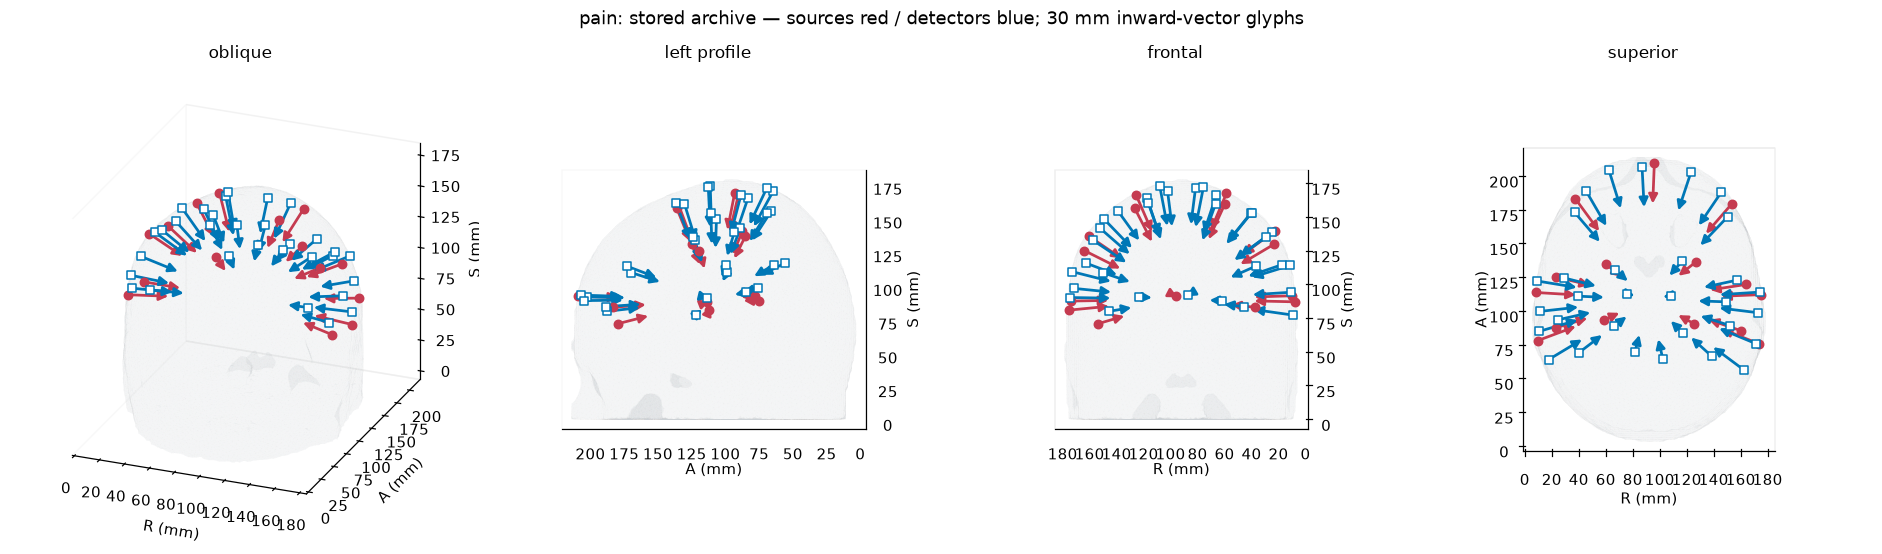

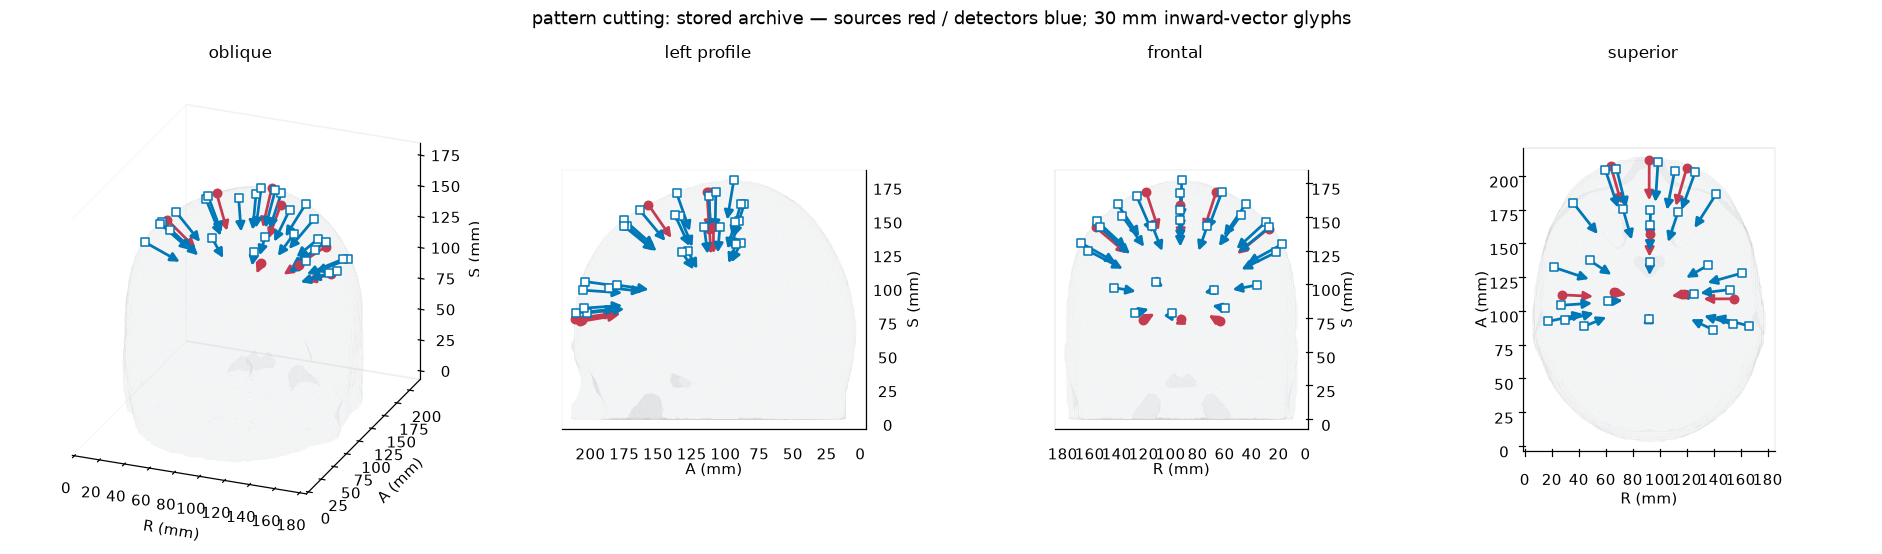

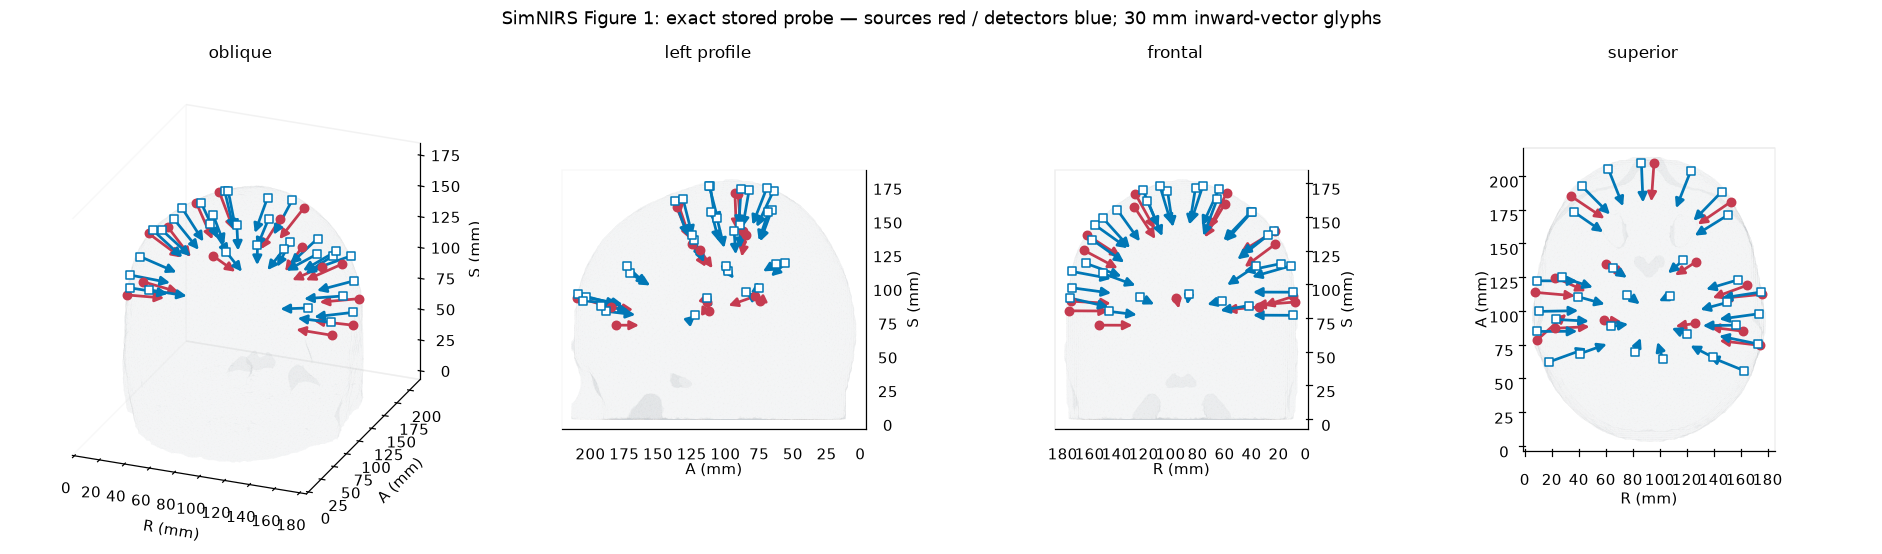

In [30]:
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d

class DirectionArrow3D(FancyArrowPatch):
    """Project true 3D endpoints, with a screen-readable arrowhead in every view."""
    def __init__(self, start, end, **kwargs):
        super().__init__((0,0),(0,0),**kwargs)
        self.points3d = np.vstack([start,end])
    def draw(self, renderer):
        x,y,z = proj3d.proj_transform(*self.points3d.T,self.axes.get_proj())
        self.set_positions((x[0],y[0]),(x[1],y[1]))
        super().draw(renderer)
    def do_3d_projection(self):
        return float(np.min(proj3d.proj_transform(*self.points3d.T,self.axes.get_proj())[2]))

def probe_arrays(probe):
    return np.vstack([probe["sourcepos"], probe["detpos"]]), np.vstack([probe["sourcedir"], probe["detnorms"]])

def draw_registration(ax, nodes, surface, probe, title, camera="oblique",
                      channels=False, labels=None, mesh_alpha=0.10):
    # As in Figure 1, draw anatomy first, then all directions/markers explicitly over it.
    ax.add_collection3d(Poly3DCollection(np.asarray(surface.vertices)[surface.faces],
        facecolors=COLORS["mesh"], edgecolors="none", alpha=mesh_alpha, rasterized=True, zorder=0))
    if channels and "channel_pairings" in probe:
        for s, d in np.unique(probe["channel_pairings"], axis=0):
            ax.plot(*np.vstack([probe["sourcepos"][s], probe["detpos"][d]]).T,
                    color="#6c7885", lw=.65, alpha=.25, zorder=2)
    for kind, pkey, dkey, marker in [("source","sourcepos","sourcedir","o"),
                                      ("detector","detpos","detnorms","s")]:
        points, directions = probe[pkey], probe[dkey]
        color = COLORS[kind]
        # Normalize a copy for glyph length; preserve the actual vector sign and 3D endpoint.
        for point,vector in zip(points,directions,strict=True):
            unit_vector = vector/np.linalg.norm(vector)
            ax.add_artist(DirectionArrow3D(point,point+ARROW_LENGTH_MM*unit_vector,
                arrowstyle="-|>",mutation_scale=12,shrinkA=0,shrinkB=0,
                color=color,linewidth=ARROW_WIDTH_PT,zorder=8))
        ax.scatter(*points.T, s=30, marker=marker, edgecolors=color,
                   facecolors=color if kind=="source" else "white", linewidths=1,
                   depthshade=False, zorder=10)
        if LABEL_OPTODES if labels is None else labels:
            for i, point in enumerate(points):
                ax.text(*point, f"{'S' if kind=='source' else 'D'}{i+1}", fontsize=7, zorder=12)
    p, _ = probe_arrays(probe)
    lower, upper = np.minimum(nodes.min(0), p.min(0))-7, np.maximum(nodes.max(0), p.max(0))+7
    ax.set(xlim=(lower[0],upper[0]), ylim=(lower[1],upper[1]), zlim=(lower[2],upper[2]),
           xlabel="R (mm)", ylabel="A (mm)", zlabel="S (mm)")
    ax.set_box_aspect(upper-lower)
    ax.set_proj_type("ortho")
    ax.view_init(*CAMERAS[camera])
    ax.grid(False)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
    # Exact orthogonal cameras collapse one 3D axis: hide its overlapping ticks.
    hidden = {"left profile": "x", "frontal": "y", "superior": "z"}.get(camera)
    if hidden:
        getattr(ax, f"set_{hidden}ticks")([])
        getattr(ax, f"set_{hidden}label")("")
        getattr(ax, hidden+"axis").line.set_color("none")
    ax.set_title(title, fontsize=11, pad=12)

def registration_gallery(nodes, surface, probe, name):
    fig = plt.figure(figsize=(17,5.2), layout="constrained")
    for i, camera in enumerate(CAMERAS):
        ax = fig.add_subplot(1,4,i+1,projection="3d",computed_zorder=False)
        draw_registration(ax,nodes,surface,probe,camera,camera)
    fig.suptitle(f"{name} — sources red / detectors blue; {ARROW_LENGTH_MM:g} mm inward-vector glyphs")
    save_figure(fig, name.replace(" ","_"))
    plt.show()
    plt.close(fig)

for name, data in datasets.items():
    registration_gallery(data["nodes"],data["surface"],data["stored"],f"{name}: stored archive")
if figure_inputs:
    figure_nodes = figure_inputs["mesh"]["nodes"]
    figure_elements = figure_inputs["mesh"]["elements"]
    figure_surface = make_surface_mesh(figure_nodes,figure_elements)
    registration_gallery(figure_nodes,figure_surface,figure_inputs["probe"],"SimNIRS Figure 1: exact stored probe")

## 3. Fresh registrations from both raw probes
Run the actual `register_probe` in this checkout with each dataset's configured orientation, units, and 0.5 mm embedding step. Results remain in memory. Compare positions and directions against the retained archives; timestamps alone cannot establish which algorithm produced an archive. The current code still describes center directions in its return docstring, but actually calls `find_smoothed_surface_directions`.

Registering pain …


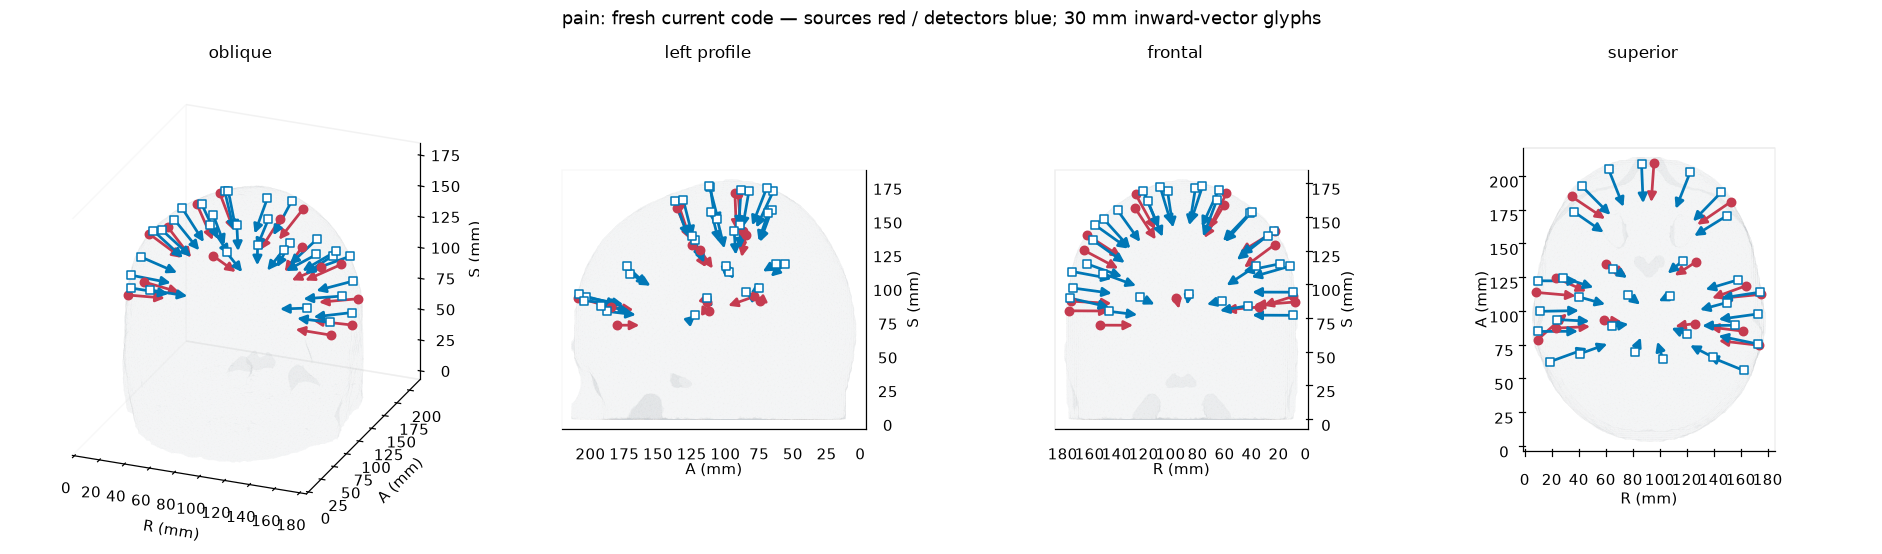

Registering pattern cutting …


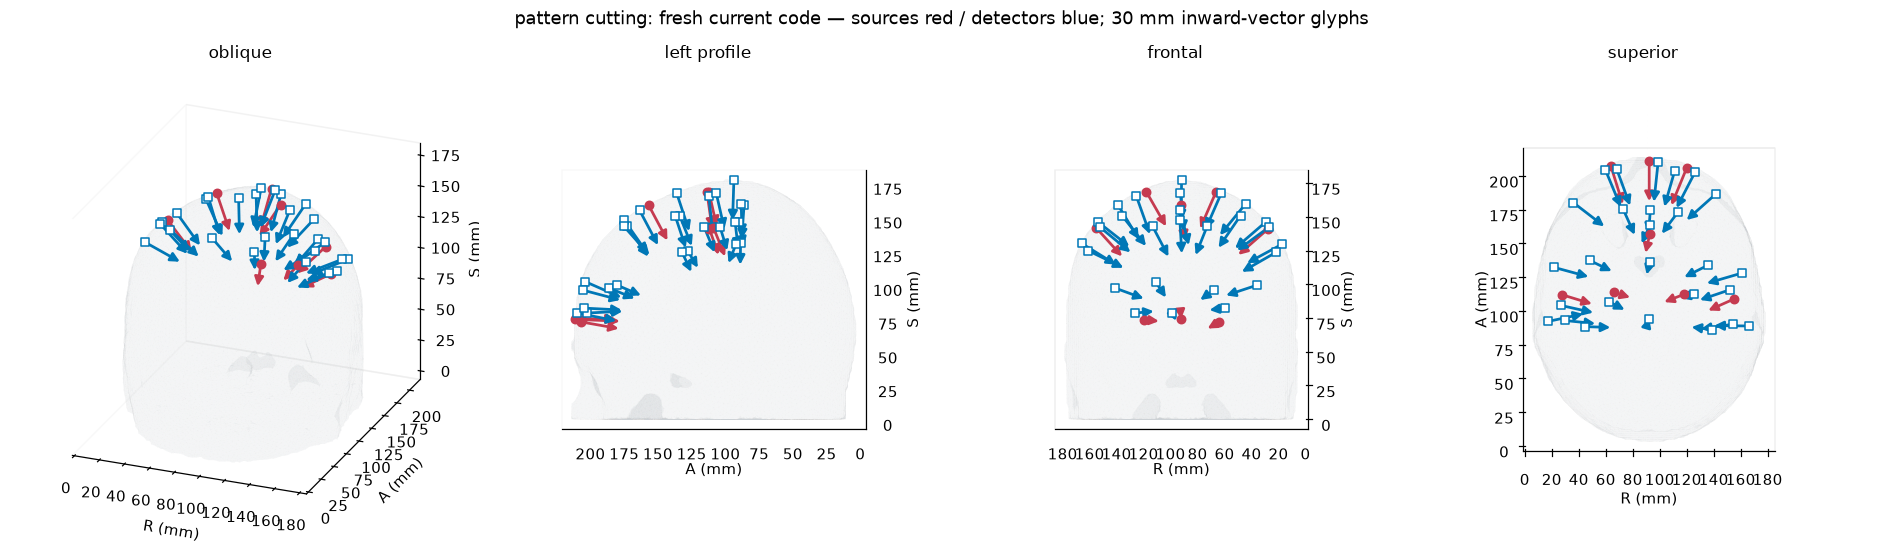

| dataset | seconds | mean_position_shift_mm | max_position_shift_mm | mean_direction_change_deg | max_direction_change_deg |
|---|---|---|---|---|---|
| pain | 16.2 | 1.282 | 6.147 | 11.43 | 24.02 |
| pattern cutting | 13.5 | 0.270 | 0.500 | 11.21 | 19.67 |

In [31]:
def angles_deg(a,b):
    a = a / np.linalg.norm(a,axis=1,keepdims=True)
    b = b / np.linalg.norm(b,axis=1,keepdims=True)
    return np.degrees(np.arccos(np.clip(np.sum(a*b,axis=1),-1,1)))

fresh_rows = []
for name, data in datasets.items():
    start = time.perf_counter()
    settings = data["config"]["probe_settings"]
    print("Registering", name, "…", flush=True)
    s,d,sd,dd,se,de = register_probe(data["raw_sources"],data["raw_detectors"],
        data["nodes"],data["elements"],probe_orientation=settings["probe_orientation"],
        probe_units=settings["probe_units"],embedding_step=settings["embedding_step"])
    data["fresh"] = dict(sourcepos=s,detpos=d,sourcedir=sd,detnorms=dd,
                          source_elements=se,detector_elements=de,channel_pairings=data["pairings"])
    p,v = probe_arrays(data["fresh"])
    oldp,oldv = probe_arrays(data["stored"])
    shift = np.linalg.norm(p-oldp,axis=1)
    angle = angles_deg(v,oldv)
    fresh_rows.append(dict(dataset=name,seconds=f"{time.perf_counter()-start:.1f}",
        mean_position_shift_mm=f"{shift.mean():.3f}",max_position_shift_mm=f"{shift.max():.3f}",
        mean_direction_change_deg=f"{angle.mean():.2f}",max_direction_change_deg=f"{angle.max():.2f}"))
    registration_gallery(data["nodes"],data["surface"],data["fresh"],f"{name}: fresh current code")
table(fresh_rows)

## 4. Direction audit and wider-neighborhood experiment
The production method uses the closest face plus its edge-adjacent faces (one ring), with area weighting and sign chosen toward the bounding-box center.

Here an independent local sign reference comes from the **owning tetrahedron**: every boundary normal points toward its tetrahedron's opposite vertex. This does not depend on face winding or a head-center heuristic. Candidate averages use connected face neighborhoods of 1, 2, 4, and 8 rings. The patch's physical extent and face count are reported; a fixed ring count does not imply a fixed millimetre scale.

Checks (diagnostic, not a clinical/transport acceptance criterion):
- finite unit directions;
- positive dot product with the owning-face inward normal (a local half-space test);
- points sampled 0.1, 1 and 5 mm from the surface along the vector lie inside a tetrahedron;
- sensitivity to moving the evaluation point ±0.5 mm in two tangent directions;
- angular change relative to the current method.

The containment samples do not prove that every intervening ray segment is inside. Larger patches can wash out curvature; center-pointing directions are a reference only. No candidate is automatically adopted.

In [32]:
def topology_and_inward_normals(nodes, elements, surface):
    # Same exterior extraction/order as make_surface_mesh, plus owning tetrahedra.
    face_columns = np.array([[0,1,2],[0,1,3],[0,2,3],[1,2,3]])
    all_faces = elements[:,face_columns].reshape(-1,3)
    _, first, counts = np.unique(np.sort(all_faces,axis=1),axis=0,return_index=True,return_counts=True)
    boundary_first = first[counts==1]
    faces = all_faces[boundary_first]
    np.testing.assert_array_equal(faces,surface.faces)
    opposite = elements[:,[3,2,1,0]].reshape(-1)[boundary_first]
    triangles = nodes[faces]
    centers = triangles.mean(axis=1)
    crosses = np.cross(triangles[:,1]-triangles[:,0],triangles[:,2]-triangles[:,0])
    twice_area = np.linalg.norm(crosses,axis=1)
    assert np.all(twice_area>0)
    normals = crosses/twice_area[:,None]
    reference = nodes[opposite]-centers
    normals[np.sum(normals*reference,axis=1)<0] *= -1
    assert np.all(np.sum(normals*reference,axis=1)>0)
    adjacency = [set() for _ in faces]
    for a,b in surface.face_adjacency:
        adjacency[a].add(int(b)); adjacency[b].add(int(a))
    return dict(normals=normals, areas=twice_area/2, centers=centers, adjacency=adjacency)

def ring_directions(surface, points, topology, rings):
    nearest, _, face_ids = trimesh.proximity.closest_point_naive(surface,points)
    result, face_counts, radii = [], [], []
    for point, face in zip(nearest,face_ids):
        visited, frontier = {int(face)}, {int(face)}
        for _ in range(rings):
            frontier = set().union(*(topology["adjacency"][i] for i in frontier))-visited
            visited.update(frontier)
        ids = np.array(sorted(visited),dtype=int)
        average = np.sum(topology["normals"][ids]*topology["areas"][ids,None],axis=0)
        assert np.linalg.norm(average)>1e-12
        result.append(average/np.linalg.norm(average))
        face_counts.append(len(ids))
        radii.append(np.linalg.norm(topology["centers"][ids]-point,axis=1).max())
    return np.asarray(result), np.asarray(face_counts), np.asarray(radii)

def containment_cache(nodes,elements):
    tetra = nodes[elements]
    edges = np.stack([tetra[:,i]-tetra[:,0] for i in (1,2,3)],axis=-1)
    valid = np.abs(np.linalg.det(edges))>np.finfo(float).eps
    return dict(lower=tetra[valid].min(1),upper=tetra[valid].max(1),
                origin=tetra[valid,0],inverse=np.linalg.inv(edges[valid]))

def inside_points(points,cache,tol=1e-9):
    # Bounding-box prefilter is exact; barycentric containment matches repository logic.
    inside = []
    for p in points:
        hit = np.all(p>=cache["lower"]-tol,axis=1)&np.all(p<=cache["upper"]+tol,axis=1)
        xyz = np.einsum("eij,ej->ei",cache["inverse"][hit],p-cache["origin"][hit])
        bary = np.column_stack([1-xyz.sum(1),xyz])
        inside.append(bool(np.any(np.all(bary>=-tol,axis=1)&np.all(bary<=1+tol,axis=1))))
    return np.asarray(inside)

audit_rows, per_optode_rows = [], []
for name,data in datasets.items():
    print("Auditing",name,"…",flush=True)
    nodes,elements,surface = data["nodes"],data["elements"],data["surface"]
    topology = topology_and_inward_normals(nodes,elements,surface)
    cache = containment_cache(nodes,elements)
    data.update(topology=topology,containment=cache)
    points,current = probe_arrays(data["fresh"])
    # Replay the translation/projection stages to recover ORIGINAL surface anchors.
    # Nearest surface points from the embedded coordinates can switch faces at edges.
    from mmcnirs.light_transport.register_probe import _minimize_surface_translation, project_optodes_just_inside
    from mmcnirs.utils.mesh_utils import make_orientation_matrices
    settings = data["config"]["probe_settings"]
    raw_points = np.vstack([data["raw_sources"],data["raw_detectors"]])
    scale = {"mm":1.0,"cm":10.0,"m":1000.0}[settings["probe_units"]]
    ras = scale * raw_points @ make_orientation_matrices()[settings["probe_orientation"]].T
    offset = (nodes.min(0)+nodes.max(0))/2 - (ras.min(0)+ras.max(0))/2
    offset[2] = nodes[:,2].max()-ras[:,2].max()
    translated = _minimize_surface_translation(ras+offset,surface)
    embedded,surface_points,embedding_directions,_,_ = project_optodes_just_inside(
        translated,surface,nodes,elements,settings["embedding_step"])
    np.testing.assert_allclose(embedded,points,atol=1e-8)
    _,_,face_ids = trimesh.proximity.closest_point_naive(surface,surface_points)
    data["embedding_directions"] = embedding_directions
    # Surface projection must match registration independently.
    assert np.all(inside_points(points,cache))
    checked = _find_containing_elements(points[:3],nodes,elements)>=0
    np.testing.assert_array_equal(inside_points(points[:3],cache),checked)
    current_recomputed,spread = find_smoothed_surface_directions(surface,surface_points,nodes)
    np.testing.assert_allclose(current,current_recomputed,atol=1e-8)
    normal = topology["normals"][face_ids]
    tangent1 = np.cross(normal,np.eye(3)[np.argmin(np.abs(normal),axis=1)])
    tangent1 /= np.linalg.norm(tangent1,axis=1,keepdims=True)
    tangent2 = np.cross(normal,tangent1)
    perturbed = np.concatenate([surface_points+.5*tangent1,surface_points-.5*tangent1,
                               surface_points+.5*tangent2,surface_points-.5*tangent2])
    methods = {"current 1 ring": current, "center reference": find_center_directions(points,nodes)}
    metadata = {}
    for rings in (1,2,4,8):
        label = f"owner normals {rings} rings"
        methods[label],counts,radii = ring_directions(surface,surface_points,topology,rings)
        metadata[label]=(counts,radii)
    data.update(methods=methods,surface_points=surface_points,face_ids=face_ids,spread=spread)
    for label,directions in methods.items():
        assert np.isfinite(directions).all()
        np.testing.assert_allclose(np.linalg.norm(directions,axis=1),1,atol=1e-8)
        if label.startswith("owner"):
            rings=int(label.split()[2])
            perturbed_directions=ring_directions(surface,perturbed,topology,rings)[0]
            counts,radii=metadata[label]
        elif label.startswith("current"):
            perturbed_directions=find_smoothed_surface_directions(surface,perturbed,nodes)[0]
            counts,radii=metadata["owner normals 1 rings"]
        else:
            perturbed_directions=find_center_directions(perturbed,nodes)
            counts,radii=np.zeros(len(points),int),np.zeros(len(points))
        sensitivity=angles_deg(np.tile(directions,(4,1)),perturbed_directions).reshape(4,-1).max(0)
        dots=np.sum(directions*normal,axis=1)
        step_checks=np.array([inside_points(surface_points+step*directions,cache) for step in (.1,1,5)])
        change=angles_deg(current,directions)
        row=dict(dataset=name,method=label,faces_median=f"{np.median(counts):.0f}",
                 patch_radius_median_mm=f"{np.median(radii):.1f}",local_outward=int((dots<=0).sum()),
                 outside_at_0p1mm=int((~step_checks[0]).sum()),
                 outside_at_1mm=int((~step_checks[1]).sum()),outside_at_5mm=int((~step_checks[2]).sum()),
                 change_mean_deg=f"{change.mean():.1f}",change_max_deg=f"{change.max():.1f}",
                 jitter_p95_deg=f"{np.percentile(sensitivity,95):.1f}",jitter_max_deg=f"{sensitivity.max():.1f}")
        audit_rows.append(row)
        for i in range(len(points)):
            per_optode_rows.append(dict(dataset=name,method=label,optode=f"S{i+1}" if i<len(data["fresh"]["sourcepos"])
                else f"D{i-len(data['fresh']['sourcepos'])+1}",local_dot=float(dots[i]),
                outside_0p1mm=bool(~step_checks[0,i]),outside_1mm=bool(~step_checks[1,i]),
                outside_5mm=bool(~step_checks[2,i]),change_deg=float(change[i]),
                jitter_deg=float(sensitivity[i]),patch_faces=int(counts[i]),patch_radius_mm=float(radii[i])))
table(audit_rows)

Auditing pain …
Auditing pattern cutting …


| dataset | method | faces_median | patch_radius_median_mm | local_outward | outside_at_0p1mm | outside_at_1mm | outside_at_5mm | change_mean_deg | change_max_deg | jitter_p95_deg | jitter_max_deg |
|---|---|---|---|---|---|---|---|---|---|---|---|
| pain | current 1 ring | 4 | 3.3 | 0 | 0 | 0 | 0 | 0.0 | 0.0 | 10.2 | 29.3 |
| pain | center reference | 0 | 0.0 | 0 | 0 | 0 | 0 | 11.5 | 24.6 | 0.4 | 0.5 |
| pain | owner normals 1 rings | 4 | 3.3 | 0 | 0 | 0 | 0 | 0.0 | 0.0 | 10.2 | 29.3 |
| pain | owner normals 2 rings | 10 | 5.2 | 0 | 0 | 0 | 0 | 3.7 | 24.8 | 5.1 | 5.9 |
| pain | owner normals 4 rings | 32 | 9.3 | 0 | 0 | 0 | 0 | 4.4 | 30.7 | 3.3 | 3.6 |
| pain | owner normals 8 rings | 114 | 17.1 | 0 | 0 | 0 | 0 | 4.2 | 28.9 | 2.2 | 4.2 |
| pattern cutting | current 1 ring | 4 | 3.3 | 0 | 0 | 0 | 0 | 0.0 | 0.0 | 9.0 | 10.3 |
| pattern cutting | center reference | 0 | 0.0 | 0 | 0 | 0 | 0 | 11.3 | 19.7 | 0.4 | 0.4 |
| pattern cutting | owner normals 1 rings | 4 | 3.3 | 0 | 0 | 0 | 0 | 0.0 | 0.0 | 9.0 | 10.3 |
| pattern cutting | owner normals 2 rings | 10 | 5.2 | 0 | 0 | 0 | 0 | 3.4 | 8.5 | 4.8 | 7.8 |
| pattern cutting | owner normals 4 rings | 32 | 9.0 | 0 | 0 | 0 | 0 | 4.4 | 11.1 | 4.0 | 5.0 |
| pattern cutting | owner normals 8 rings | 114 | 17.1 | 0 | 0 | 0 | 0 | 4.5 | 10.4 | 2.5 | 4.7 |

## 5. Compare wider neighborhoods at fixed registered positions
The same camera, physical arrow length, and positions are used in every panel. The 1-ring owner-normal method separates sign orientation from neighborhood size; 2/4/8-ring variants then change neighborhood size only. Select cameras and methods below. Per-optode tables expose the largest changes and any containment failures.

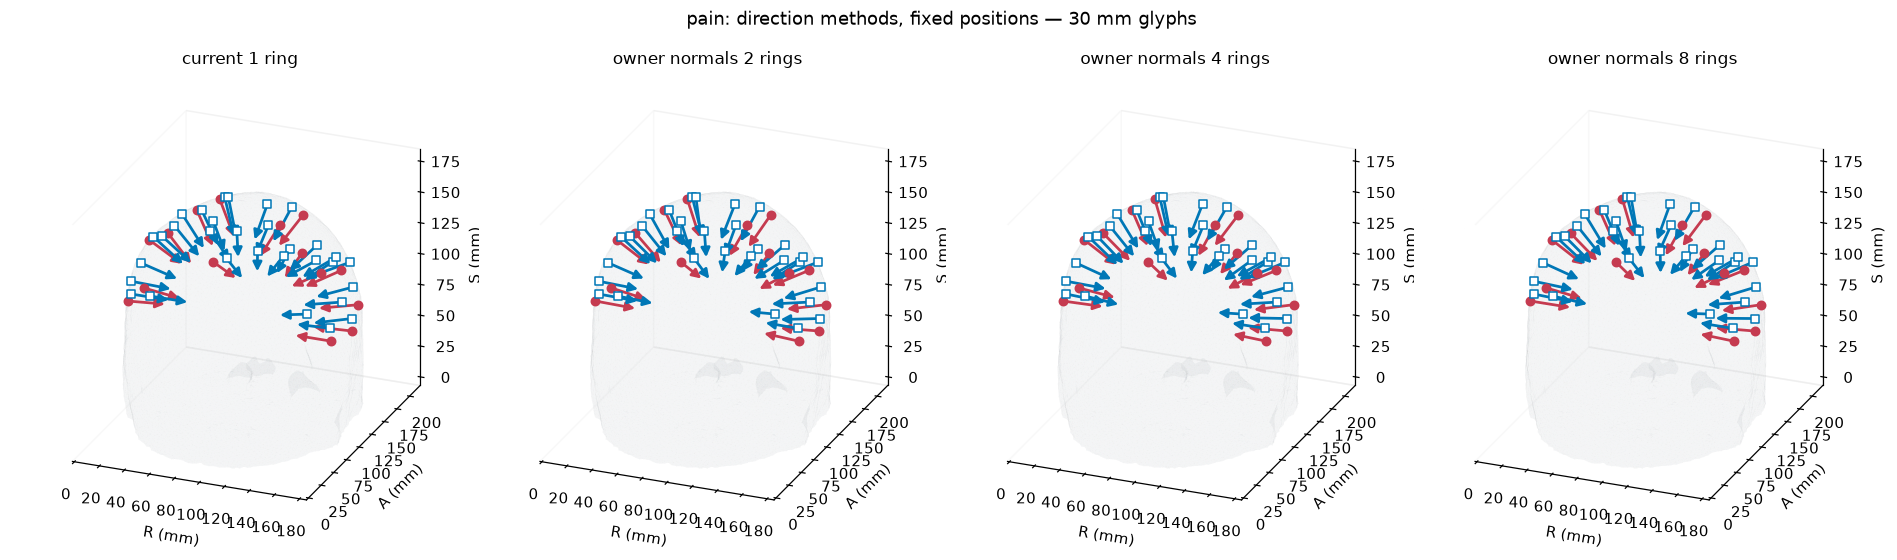

| dataset | method | optode | local_dot | outside_0p1mm | outside_1mm | outside_5mm | change_deg | jitter_deg | patch_faces | patch_radius_mm |
|---|---|---|---|---|---|---|---|---|---|---|
| pain | owner normals 4 rings | S2 | 0.71 | False | False | False | 30.71 | 1.51 | 29 | 7.55 |
| pain | owner normals 4 rings | D17 | 0.98 | False | False | False | 12.24 | 2.20 | 30 | 9.34 |
| pain | owner normals 4 rings | D18 | 0.98 | False | False | False | 11.79 | 1.85 | 32 | 8.56 |
| pain | owner normals 4 rings | D27 | 0.98 | False | False | False | 7.44 | 2.97 | 31 | 8.66 |
| pain | owner normals 4 rings | S3 | 0.98 | False | False | False | 7.22 | 0.53 | 33 | 9.80 |
| pain | owner normals 4 rings | D26 | 0.98 | False | False | False | 6.66 | 0.00 | 33 | 9.72 |
| pain | owner normals 4 rings | S14 | 0.99 | False | False | False | 6.48 | 3.05 | 30 | 9.53 |
| pain | owner normals 4 rings | S12 | 0.98 | False | False | False | 6.33 | 0.81 | 27 | 6.78 |

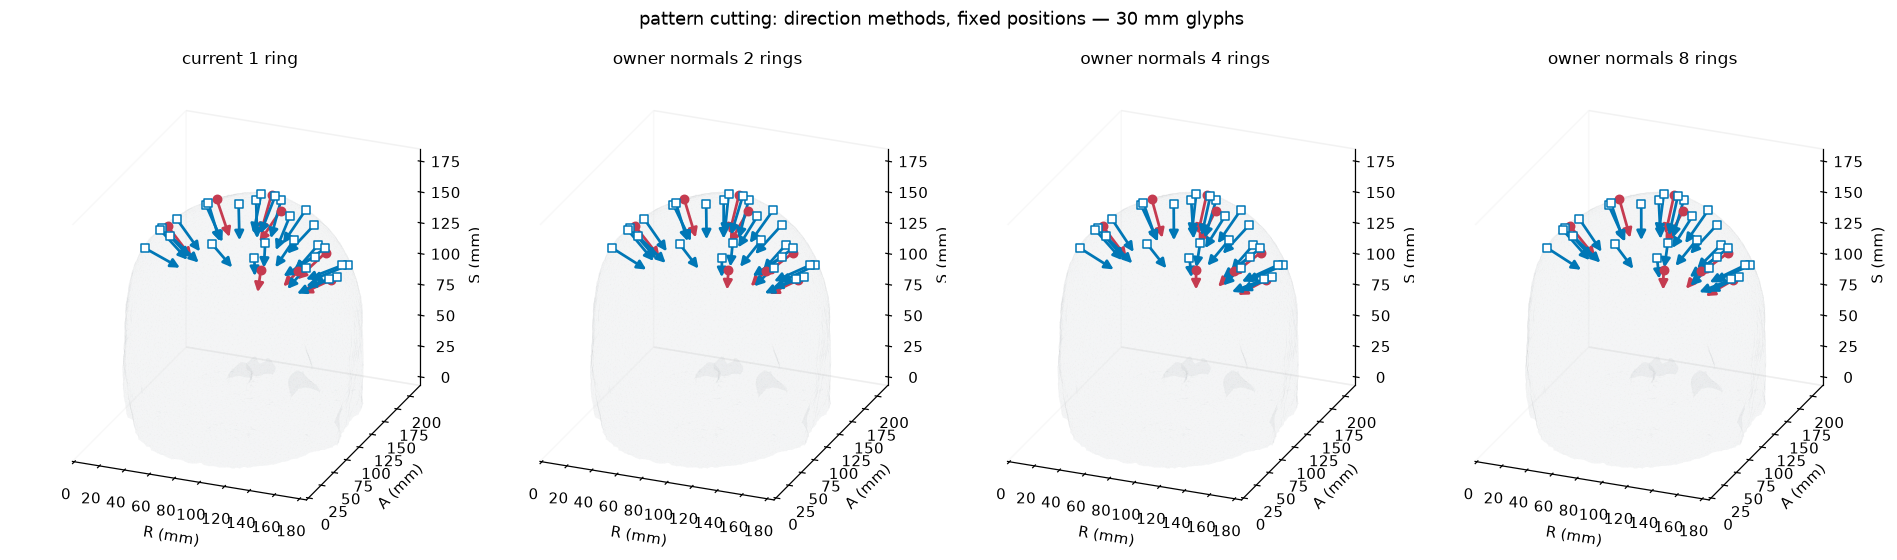

| dataset | method | optode | local_dot | outside_0p1mm | outside_1mm | outside_5mm | change_deg | jitter_deg | patch_faces | patch_radius_mm |
|---|---|---|---|---|---|---|---|---|---|---|
| pattern cutting | owner normals 4 rings | D27 | 0.98 | False | False | False | 11.14 | 3.05 | 31 | 9.83 |
| pattern cutting | owner normals 4 rings | D6 | 0.96 | False | False | False | 10.12 | 0.00 | 32 | 8.70 |
| pattern cutting | owner normals 4 rings | D25 | 0.92 | False | False | False | 9.50 | 1.13 | 33 | 8.83 |
| pattern cutting | owner normals 4 rings | D18 | 0.99 | False | False | False | 9.20 | 0.87 | 33 | 9.19 |
| pattern cutting | owner normals 4 rings | D22 | 0.99 | False | False | False | 7.77 | 0.32 | 33 | 8.87 |
| pattern cutting | owner normals 4 rings | S7 | 0.99 | False | False | False | 6.71 | 1.82 | 33 | 8.69 |
| pattern cutting | owner normals 4 rings | S6 | 0.97 | False | False | False | 6.65 | 1.20 | 30 | 8.32 |
| pattern cutting | owner normals 4 rings | S1 | 0.98 | False | False | False | 6.61 | 0.66 | 31 | 10.34 |

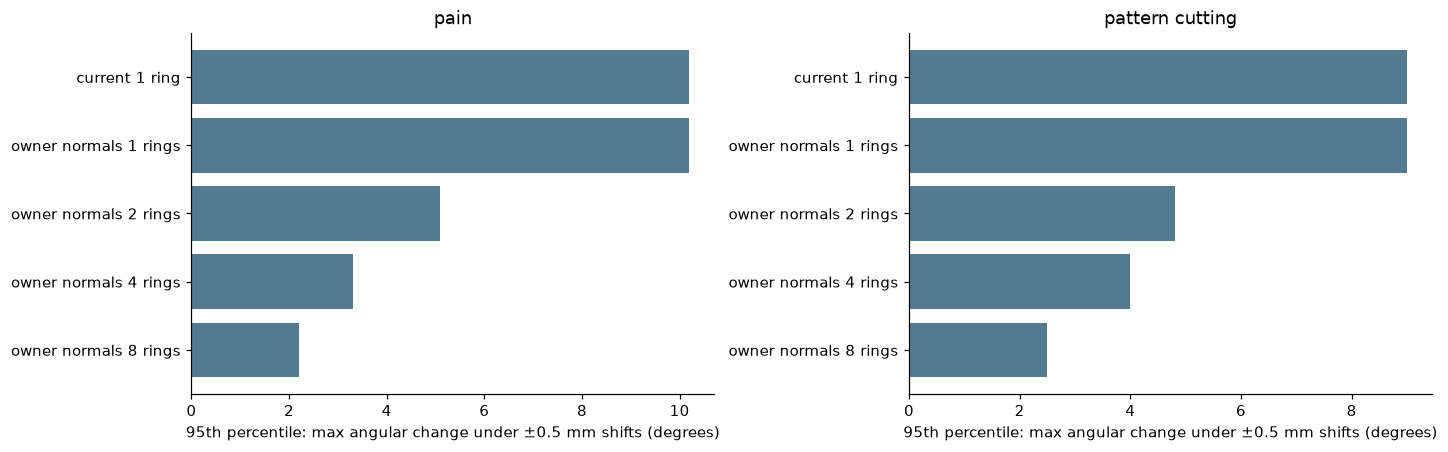

In [33]:
COMPARE_CAMERA = "oblique"
COMPARE_METHODS = ["current 1 ring","owner normals 2 rings","owner normals 4 rings","owner normals 8 rings"]
for name,data in datasets.items():
    fig = plt.figure(figsize=(17,5.3),layout="constrained")
    ns = len(data["fresh"]["sourcepos"])
    for i,method in enumerate(COMPARE_METHODS):
        probe = dict(data["fresh"],sourcedir=data["methods"][method][:ns],detnorms=data["methods"][method][ns:])
        ax = fig.add_subplot(1,len(COMPARE_METHODS),i+1,projection="3d",computed_zorder=False)
        draw_registration(ax,data["nodes"],data["surface"],probe,method,COMPARE_CAMERA)
    fig.suptitle(f"{name}: direction methods, fixed positions — {ARROW_LENGTH_MM:g} mm glyphs")
    save_figure(fig,name.replace(" ","_")+"_direction_methods")
    plt.show(); plt.close(fig)
    relevant=[r for r in per_optode_rows if r["dataset"]==name and r["method"]=="owner normals 4 rings"]
    worst=sorted(relevant,key=lambda r:r["change_deg"],reverse=True)[:8]
    table([{k:(f"{v:.2f}" if isinstance(v,float) else v) for k,v in r.items()} for r in worst])

# A linear-scale stability comparison; lower jitter is more stable, not automatically more correct.
fig,axs=plt.subplots(1,2,figsize=(13,4),layout="constrained")
for ax,(name,data) in zip(axs,datasets.items()):
    rows=[r for r in audit_rows if r["dataset"]==name and r["method"]!="center reference"]
    ax.barh([r["method"] for r in rows],[float(r["jitter_p95_deg"]) for r in rows],color="#527b91")
    ax.set(xlabel="95th percentile: max angular change under ±0.5 mm shifts (degrees)",
           title=name,xlim=(0,None))
    ax.invert_yaxis(); ax.spines[["top","right"]].set_visible(False)
plt.show(); plt.close(fig)

## 6. Recreate the pain current-versus-legacy comparison
This adapts `legacy/pain_data/visualize_registered_probes.py`: fresh registration, historical registration, and position overlay. The old script's documented X reflection is shown explicitly as a **frame-conversion hypothesis**, not accepted ground truth. Both the as-saved and reflected variants are measured below, along with `correct_legacy_probe.npz` when present.

If the historical archive has no source directions, source arrows use an explicitly labeled center-pointing reconstruction; detector arrows retain the historical vectors (transformed with positions). Direction normalization is for display only. The comparison does not establish that the historical montage is anatomically correct.

legacy_probe.npz {'detnorms': (31, 3), 'detpos': (31, 3), 'sourcepos': (15, 3)}
correct_legacy_probe.npz {'sourcepos': (15, 3), 'detpos': (31, 3), 'detnorms': (31, 3)}


| variant | sources | detectors | source_directions | mean_shift_to_fresh_mm | max_shift_to_fresh_mm | mean_surface_distance_mm | outside_count |
|---|---|---|---|---|---|---|---|
| legacy_probe.npz as saved | 15 | 31 | ABSENT | 103.12 | 166.92 | 0.49 | 0 |
| legacy_probe.npz X reflected | 15 | 31 | ABSENT | 6.03 | 10.09 | 0.93 | 14 |
| correct_legacy_probe.npz as saved | 15 | 31 | ABSENT | 5.65 | 9.17 | 0.47 | 0 |
| correct_legacy_probe.npz X reflected | 15 | 31 | ABSENT | 104.07 | 167.35 | 0.72 | 17 |

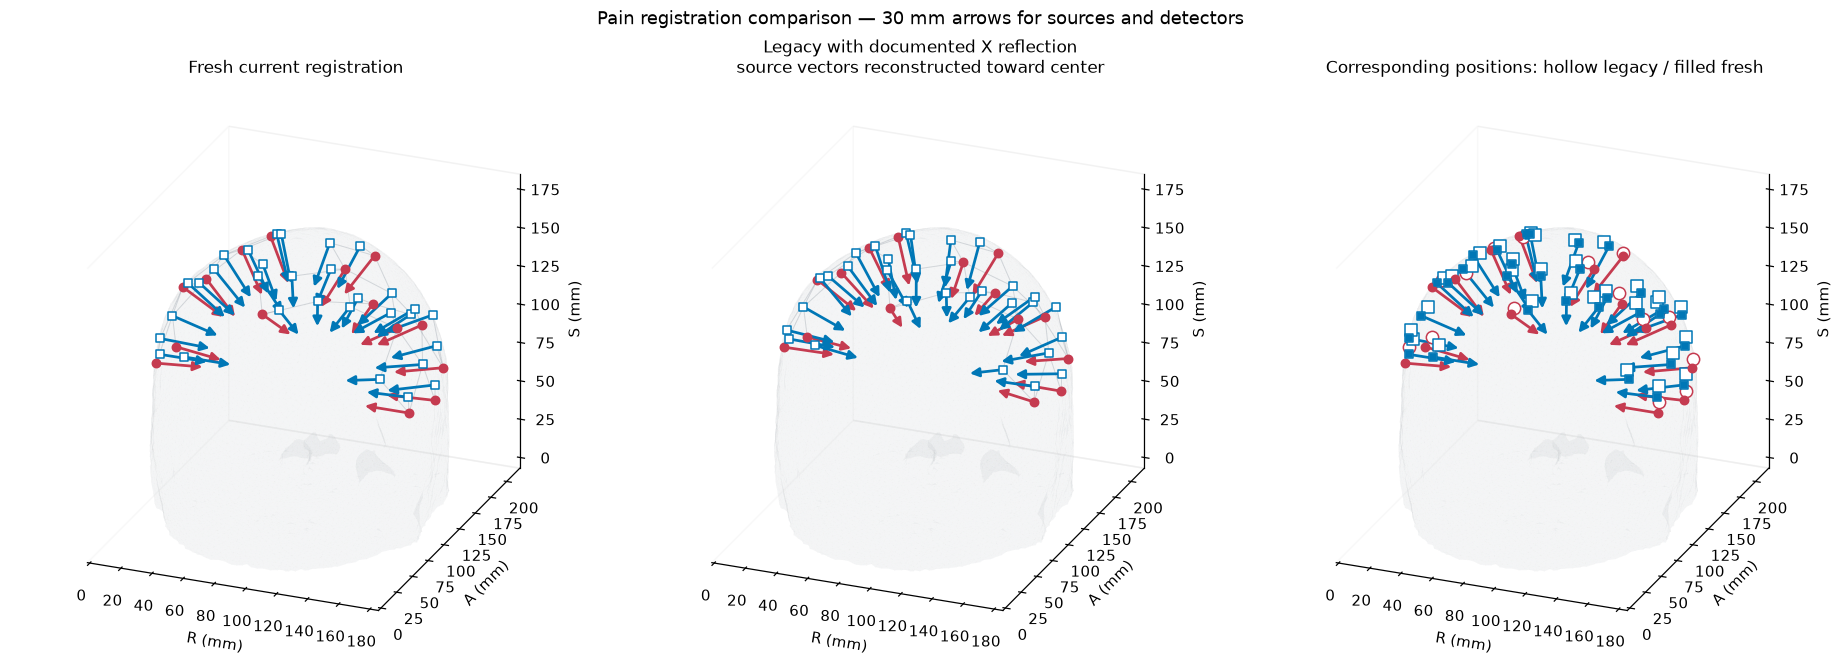

In [34]:
pain = datasets["pain"]
legacy_variants = {}
for filename in ("legacy_probe.npz","correct_legacy_probe.npz"):
    path = pain["directory"]/filename
    if not path.is_file():
        continue
    archive = load_npz(path)
    print(filename, {k:v.shape for k,v in archive.items()})
    provenance.append(dict(dataset="pain legacy comparison",path=str(path.relative_to(ROOT)),sha256=sha256(path)))
    legacy_variants[filename+" as saved"] = archive
    reflected = {k:v.copy() for k,v in archive.items()}
    midpoint = (pain["nodes"][:,0].min()+pain["nodes"][:,0].max())/2
    for key in ("sourcepos","detpos"):
        reflected[key][:,0] = 2*midpoint-reflected[key][:,0]
    for key in ("sourcedir","detnorms"):
        if key in reflected:
            reflected[key][:,0] *= -1
    legacy_variants[filename+" X reflected"] = reflected

legacy_rows=[]
for name,probe in legacy_variants.items():
    p=np.vstack([probe["sourcepos"],probe["detpos"]])
    currentp,_=probe_arrays(pain["fresh"])
    nearest,distance,_=trimesh.proximity.closest_point_naive(pain["surface"],p)
    error=np.linalg.norm(p-currentp,axis=1)
    legacy_rows.append(dict(variant=name,sources=len(probe["sourcepos"]),detectors=len(probe["detpos"]),
        source_directions="stored" if "sourcedir" in probe else "ABSENT",
        mean_shift_to_fresh_mm=f"{error.mean():.2f}",max_shift_to_fresh_mm=f"{error.max():.2f}",
        mean_surface_distance_mm=f"{distance.mean():.2f}",outside_count=int((~inside_points(p,pain["containment"])).sum())))
table(legacy_rows)

LEGACY_VARIANT = "legacy_probe.npz X reflected"  # Reproduce the old comparison script's convention.
legacy = {k:v.copy() for k,v in legacy_variants[LEGACY_VARIANT].items()}
legacy_source_note = "stored source vectors"
if "sourcedir" not in legacy:
    legacy["sourcedir"] = find_center_directions(legacy["sourcepos"],pain["nodes"])
    legacy_source_note = "source vectors reconstructed toward center"
legacy["channel_pairings"] = pain["pairings"]
assert legacy["sourcepos"].shape == pain["fresh"]["sourcepos"].shape
assert legacy["detpos"].shape == pain["fresh"]["detpos"].shape

fig=plt.figure(figsize=(17,6),layout="constrained")
axes=[fig.add_subplot(1,3,i+1,projection="3d",computed_zorder=False) for i in range(3)]
draw_registration(axes[0],pain["nodes"],pain["surface"],pain["fresh"],"Fresh current registration",channels=True)
draw_registration(axes[1],pain["nodes"],pain["surface"],legacy,
                  "Legacy with documented X reflection\n"+legacy_source_note,channels=True)
draw_registration(axes[2],pain["nodes"],pain["surface"],pain["fresh"],"Corresponding positions: hollow legacy / filled fresh")
for pkey,kind,marker in [("sourcepos","source","o"),("detpos","detector","s")]:
    old,new=legacy[pkey],pain["fresh"][pkey]
    color=COLORS[kind]
    for a,b in zip(old,new,strict=True):
        axes[2].plot(*np.vstack([a,b]).T,color=color,lw=.8,alpha=.5,zorder=5)
    axes[2].scatter(*old.T,s=65,marker=marker,edgecolors=color,facecolors="white",depthshade=False,zorder=9)
    axes[2].scatter(*new.T,s=18,marker=marker,color=color,depthshade=False,zorder=10)
fig.suptitle(f"Pain registration comparison — {ARROW_LENGTH_MM:g} mm arrows for sources and detectors")
save_figure(fig,"pain_registered_probe_comparison")
plt.show(); plt.close(fig)

## 7. Unified radius-robustness experiment: 3–18 mm in 0.5 mm steps
This replaces the separate coarse/fine sweeps. The pain study fixes the **exact Figure 1 positions**; pattern cutting fixes the fresh registration. Each radius averages owning-tetrahedron inward normals over a connected surface patch, weighted by triangle area.

**Robustness has two separate demands**, evaluated per optode:
1. **Position sensitivity:** worst 3D direction change for evaluation-point shifts of **0.5 mm and 1 mm**, in eight tangent-plane directions, followed by reprojection to the surface. These are deterministic stress tests, not an uncertainty distribution.
2. **Radius stability:** the largest pairwise angle among all directions from the tested radius through 18 mm. This tests whether a small radius step merely hides a slower drift.

For a tolerance T, an optode passes only if its **1 mm position sensitivity stays ≤T at every larger tested radius**, its full remaining radius span has angular diameter ≤T, and all larger-radius base vectors pass the local inward and 0.1/1/5 mm sampled containment checks. The first radius passing is reported for T = **1°, 2°, 3°, 5°**. A candidate must leave at least **2 mm of larger radii** for assessment (so no radius above 16 mm can be selected just because the sweep ends).

**2° is an explicit working tolerance, not a physical standard.** Reports distinguish 95% of optodes from all optodes. “Enough” depends on that tolerance and coverage. Agreement with stored vectors is shown only as context. Large radii can be stable while smoothing away real curvature. Perturbed-vector containment is not tested; geometric checks apply to base positions. The experiment assesses direction sensitivity, not registration accuracy or photon transport.

In [35]:
# Unified controls: one dense sweep replaces the former coarse/fine result sections.
ROBUST_RADII_MM = np.arange(3.0,18.0+0.25,0.5)
ROBUST_QUANTILES = (0.10,0.90)
PERTURBATION_MM = (0.5,1.0)
ROBUST_TOLERANCES_DEG = (1.0,2.0,3.0,5.0)
WORKING_TOLERANCE_DEG = 2.0  # Explicit exploratory tolerance, not an established physical standard.
MIN_REMAINING_RADIUS_SPAN_MM = 2.0
pain_exact = figure_inputs["probe"] if figure_inputs else datasets["pain"]["stored"]
pain_data = datasets["pain"]
exact_ns = len(pain_exact["sourcepos"])

def radius_directions(surface,points,topology,radius_mm):
    if radius_mm<=0:
        raise ValueError("radius_mm must be positive")
    anchors,_,face_ids=trimesh.proximity.closest_point_naive(surface,points)
    directions,patch_sizes,patch_ids=[],[],[]
    for anchor,face in zip(anchors,face_ids):
        allowed=np.linalg.norm(topology["centers"]-anchor,axis=1)<=radius_mm
        allowed[int(face)]=True
        visited,frontier={int(face)},{int(face)}
        while frontier:
            candidates=set().union(*(topology["adjacency"][i] for i in frontier))-visited
            frontier={i for i in candidates if allowed[i]}
            visited.update(frontier)
        ids=np.asarray(sorted(visited),int)
        vector=np.sum(topology["normals"][ids]*topology["areas"][ids,None],axis=0)
        if np.linalg.norm(vector)<1e-12:
            raise RuntimeError("Neighborhood normals cancel")
        directions.append(vector/np.linalg.norm(vector))
        patch_sizes.append(len(ids)); patch_ids.append(ids)
    return np.asarray(directions),np.asarray(patch_sizes),patch_ids


def connected_radius_sweep(anchors,face_ids,topology,radii):
    """Same radius rule as radius_directions, with one cached KD query per anchor."""
    radii=np.asarray(radii,float)
    centers=topology["centers"]
    tree=cKDTree(centers)
    near_lists=tree.query_ball_point(anchors,float(radii.max()))
    vectors=np.empty((len(radii),len(anchors),3))
    sizes=np.empty((len(radii),len(anchors)),int)
    for i,(anchor,face,near) in enumerate(zip(anchors,face_ids,near_lists,strict=True)):
        near=np.unique(np.r_[near,int(face)]).astype(int)
        distances=np.linalg.norm(centers[near]-anchor,axis=1)
        for j,radius in enumerate(radii):
            allowed=set(near[distances<=radius])
            allowed.add(int(face))
            visited,frontier={int(face)},{int(face)}
            while frontier:
                candidates=set().union(*(topology["adjacency"][k] for k in frontier))-visited
                frontier=candidates&allowed
                visited.update(frontier)
            ids=np.asarray(sorted(visited),int)
            vector=np.sum(topology["normals"][ids]*topology["areas"][ids,None],axis=0)
            length=np.linalg.norm(vector)
            if length<1e-12:
                raise RuntimeError("Neighborhood normals cancel")
            vectors[j,i]=vector/length
            sizes[j,i]=len(ids)
    return vectors,sizes

def make_fast_containment(cache):
    center=(cache["lower"]+cache["upper"])/2
    half_diagonal=np.linalg.norm(cache["upper"]-cache["lower"],axis=1)/2
    return dict(cache=cache,tree=cKDTree(center),query_radius=float(half_diagonal.max())+1e-8)

def inside_points_fast(points,fast,tol=1e-9):
    # A global bounding-sphere radius is conservative for every tetrahedral AABB.
    cache=fast["cache"]
    candidate_lists=fast["tree"].query_ball_point(points,fast["query_radius"])
    inside=np.zeros(len(points),bool)
    for i,(p,candidates) in enumerate(zip(points,candidate_lists,strict=True)):
        ids=np.asarray(candidates,int)
        ids=ids[np.all(p>=cache["lower"][ids]-tol,axis=1)&np.all(p<=cache["upper"][ids]+tol,axis=1)]
        xyz=np.einsum("eij,ej->ei",cache["inverse"][ids],p-cache["origin"][ids])
        bary=np.column_stack([1-xyz.sum(1),xyz])
        inside[i]=np.any(np.all(bary>=-tol,axis=1)&np.all(bary<=1+tol,axis=1))
    return inside

radius_studies={}
for name,probe in [("pain",pain_exact),("pattern cutting",datasets["pattern cutting"]["fresh"])]:
    start=time.perf_counter()
    data=datasets[name]
    surface,topology=data["surface"],data["topology"]
    positions,stored_vectors=probe_arrays(probe)
    anchors,_,face_ids=trimesh.proximity.closest_point_naive(surface,positions)
    normals=topology["normals"][face_ids]
    tangent1=np.cross(normals,np.eye(3)[np.argmin(np.abs(normals),axis=1)])
    tangent1/=np.linalg.norm(tangent1,axis=1,keepdims=True)
    tangent2=np.cross(normals,tangent1)
    directions2d=np.arange(8)*np.pi/4
    tangent_offsets=(np.cos(directions2d)[:,None,None]*tangent1[None]
                     +np.sin(directions2d)[:,None,None]*tangent2[None])
    print(f"{name}: base vectors for {len(positions)} optodes × {len(ROBUST_RADII_MM)} radii …",flush=True)
    vectors,counts=connected_radius_sweep(anchors,face_ids,topology,ROBUST_RADII_MM)
    np.testing.assert_allclose(np.linalg.norm(vectors,axis=-1),1,atol=1e-8)
    # Independent reference check against the original full-surface implementation.
    for radius in (3.0,6.0,12.0,18.0):
        column=int(np.flatnonzero(np.isclose(ROBUST_RADII_MM,radius))[0])
        ref,ref_counts,_=radius_directions(surface,anchors,topology,radius)
        np.testing.assert_allclose(vectors[column],ref,atol=1e-12)
        np.testing.assert_array_equal(counts[column],ref_counts)
    perturbed=np.stack([anchors+amplitude*tangent_offsets for amplitude in PERTURBATION_MM])
    query=perturbed.reshape(-1,3)
    perturbed_anchors,_,perturbed_faces=trimesh.proximity.closest_point_naive(surface,query)
    print(f"{name}: perturbation sweep, {len(query)} projected locations …",flush=True)
    perturb_vectors,_=connected_radius_sweep(perturbed_anchors,perturbed_faces,topology,ROBUST_RADII_MM)
    perturb_vectors=perturb_vectors.reshape(len(ROBUST_RADII_MM),len(PERTURBATION_MM),8,len(positions),3)
    dot=np.sum(perturb_vectors*vectors[:,None,None,:,:],axis=-1)
    jitter=np.degrees(np.arccos(np.clip(dot,-1,1))).max(axis=2)  # radius, amplitude, optode
    jitter_by_amplitude={amplitude:jitter[:,i,:].T for i,amplitude in enumerate(PERTURBATION_MM)}
    pairwise_dot=np.einsum("rni,sni->nrs",vectors,vectors)
    pairwise_angle=np.degrees(np.arccos(np.clip(pairwise_dot,-1,1)))
    radius_tail_diameter=np.column_stack([
        pairwise_angle[:,j:,j:].max(axis=(1,2)) for j in range(len(ROBUST_RADII_MM))])
    persistent_jitter=np.maximum.accumulate(jitter_by_amplitude[1.0][:,::-1],axis=1)[:,::-1]
    score=np.maximum(persistent_jitter,radius_tail_diameter)
    print(f"{name}: local-inward and tetrahedral containment checks …",flush=True)
    fast=make_fast_containment(data["containment"])
    # Check accelerated containment against the original exact barycentric routine,
    # including both inside and outside locations.
    validation_points=np.vstack([positions,anchors+.1*normals,anchors-.1*normals])
    np.testing.assert_array_equal(inside_points_fast(validation_points,fast),
                                  inside_points(validation_points,data["containment"]))
    steps=np.array([.1,1.0,5.0])
    ray_points=anchors[None,None,:,:]+steps[:,None,None,None]*vectors[None,:,:,:]
    ray_inside=inside_points_fast(ray_points.reshape(-1,3),fast).reshape(3,len(ROBUST_RADII_MM),len(positions))
    local_dot=np.einsum("rni,ni->rn",vectors,normals)
    geometry_ok=(ray_inside.all(axis=0)&(local_dot>0)).T
    persistent_geometry=np.logical_and.accumulate(geometry_ok[:,::-1],axis=1)[:,::-1]
    change_from_stored=np.stack([angles_deg(stored_vectors,v) for v in vectors],axis=1)
    ns=len(probe["sourcepos"])
    labels=[f"S{i+1}" for i in range(ns)]+[f"D{i+1}" for i in range(len(positions)-ns)]
    groups={"All optodes":np.arange(len(positions)),"Sources":np.arange(ns),
            "Detectors":np.arange(ns,len(positions))}
    radius_studies[name]=dict(probe=probe,positions=positions,anchors=anchors,face_ids=face_ids,
        vectors=vectors,counts=counts,jitter=jitter_by_amplitude,tail_diameter=radius_tail_diameter,
        persistent_jitter=persistent_jitter,score=score,geometry_ok=geometry_ok,
        persistent_geometry=persistent_geometry,change_from_stored=change_from_stored,
        labels=labels,groups=groups,ray_inside=ray_inside,local_dot=local_dot)
    print(f"{name}: done in {time.perf_counter()-start:.1f} s; "
          f"outward={int((local_dot<=0).sum())}, outside sampled ray points={int((~ray_inside).sum())}",flush=True)

print("One unified sweep:",ROBUST_RADII_MM[0],"to",ROBUST_RADII_MM[-1],
      "mm in",np.diff(ROBUST_RADII_MM)[0],"mm steps.")


pain: base vectors for 46 optodes × 31 radii …
pain: perturbation sweep, 736 projected locations …
pain: local-inward and tetrahedral containment checks …
pain: done in 5.2 s; outward=0, outside sampled ray points=0
pattern cutting: base vectors for 35 optodes × 31 radii …
pattern cutting: perturbation sweep, 560 projected locations …
pattern cutting: local-inward and tetrahedral containment checks …
pattern cutting: done in 3.8 s; outward=0, outside sampled ray points=0
One unified sweep: 3.0 to 18.0 mm in 0.5 mm steps.


## 8. Robustness curves and smallest sufficient radius
The curves show current-radius sensitivity and remaining-radius drift separately; the decision table applies the stricter **persistent** rule defined above. Each band is the 10th–90th percentile across optodes, not a confidence interval. The 95% decision requires an actual passing fraction ≥95%, rather than only a rounded quantile.

Every recommendation is limited to this tested mesh, these montage locations, the specified perturbations, and the 18 mm upper bound. The smallest radius meeting the tolerance is a candidate for review, not an automatic production change.

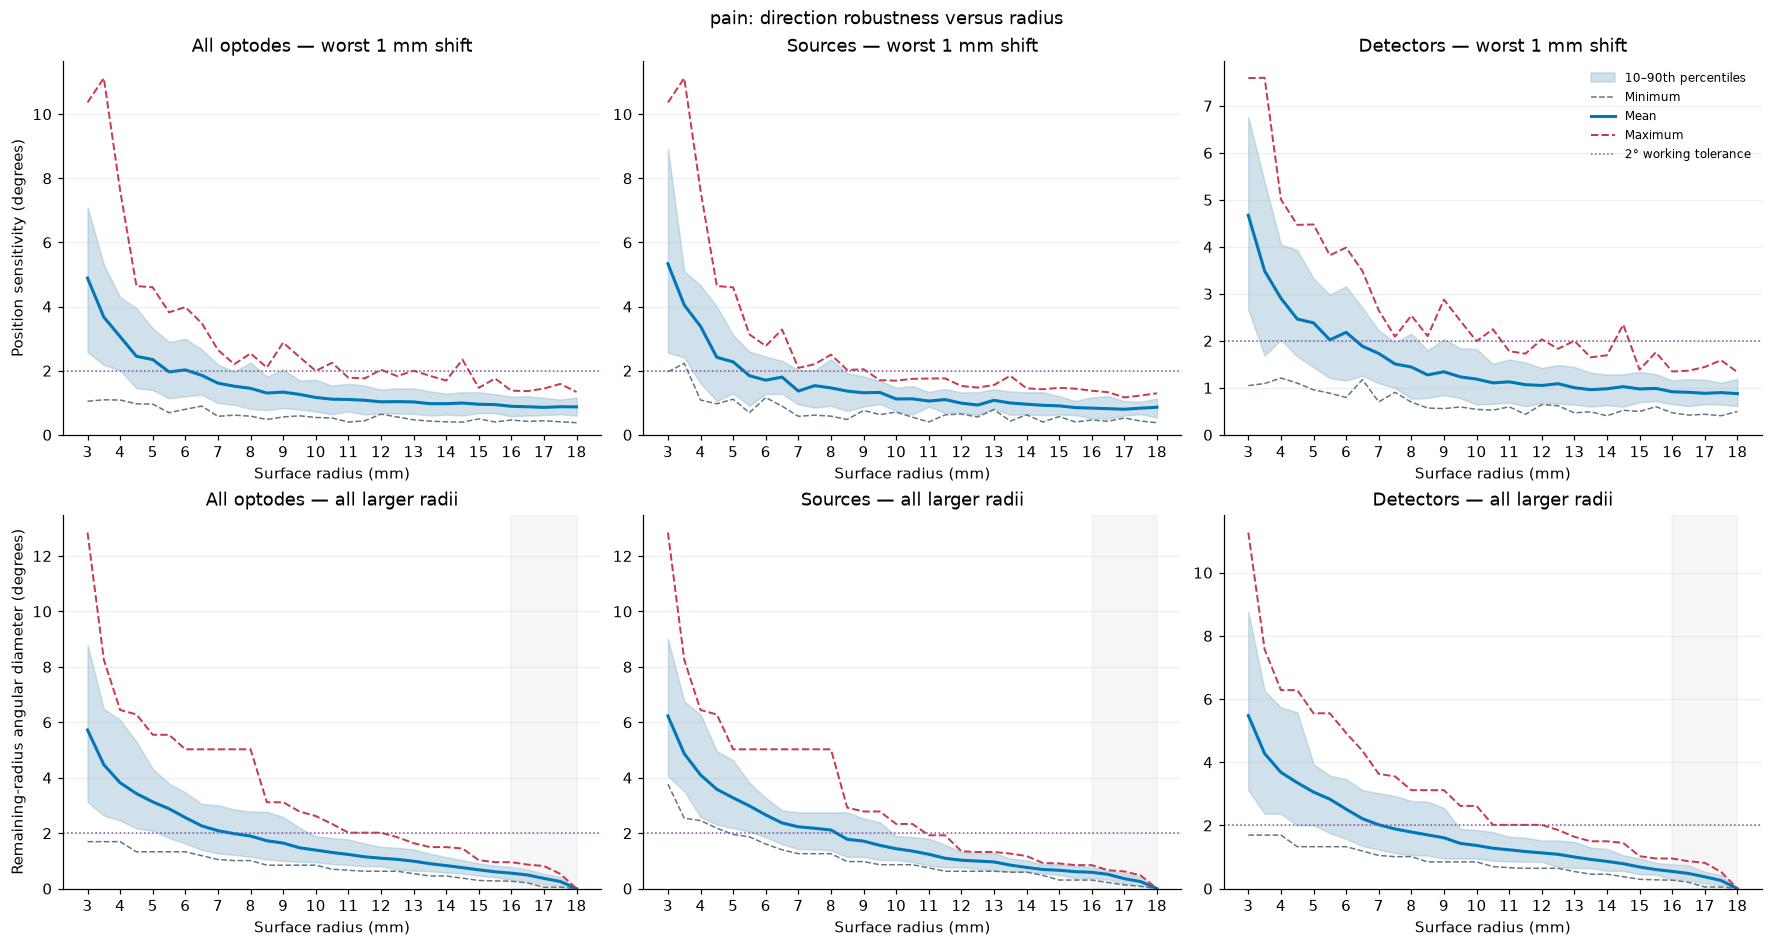

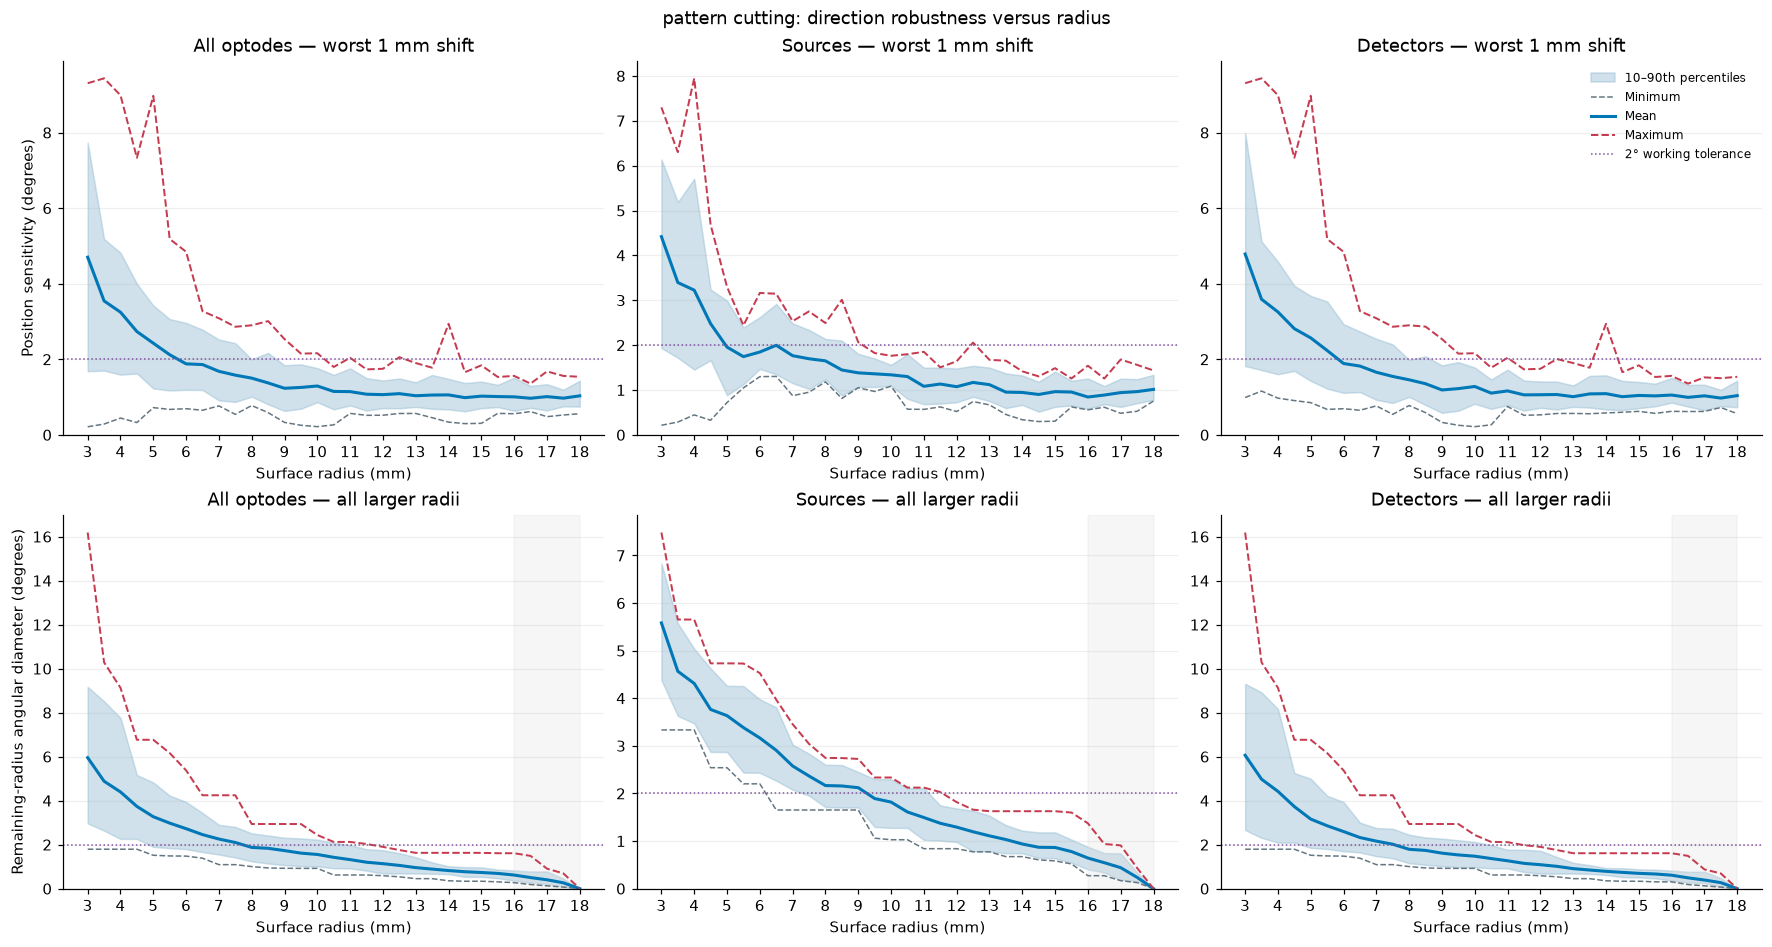

| dataset | group | tolerance_deg | radius_for_at_least_95pct_mm | radius_for_all_optodes_mm |
|---|---|---|---|---|
| pain | All optodes | 1 | not reached | not reached |
| pain | All optodes | 2 | 12.5 | 15 |
| pain | All optodes | 3 | 8.5 | 9.5 |
| pain | All optodes | 5 | 5 | 8.5 |
| pain | Sources | 1 | not reached | not reached |
| pain | Sources | 2 | 11 | 11 |
| pain | Sources | 3 | 8.5 | 8.5 |
| pain | Sources | 5 | 8.5 | 8.5 |
| pain | Detectors | 1 | not reached | not reached |
| pain | Detectors | 2 | 13.5 | 15 |
| pain | Detectors | 3 | 8.5 | 9.5 |
| pain | Detectors | 5 | 5 | 6 |
| pattern cutting | All optodes | 1 | not reached | not reached |
| pattern cutting | All optodes | 2 | 13 | 14.5 |
| pattern cutting | All optodes | 3 | 8 | 9 |
| pattern cutting | All optodes | 5 | 6 | 6.5 |
| pattern cutting | Sources | 1 | not reached | not reached |
| pattern cutting | Sources | 2 | 13 | 13 |
| pattern cutting | Sources | 3 | 9 | 9 |
| pattern cutting | Sources | 5 | 4.5 | 4.5 |
| pattern cutting | Detectors | 1 | not reached | not reached |
| pattern cutting | Detectors | 2 | 13 | 14.5 |
| pattern cutting | Detectors | 3 | 7.5 | 8 |
| pattern cutting | Detectors | 5 | 6 | 6.5 |

| tolerance_deg | each_probe_95pct_mm | every_optode_both_probes_mm |
|---|---|---|
| 1 | not reached | not reached |
| 2 | 13 | 15 |
| 3 | 8.5 | 9.5 |
| 5 | 6 | 8.5 |

Working-tolerance candidates, all optodes: {'pain': 15.0, 'pattern cutting': 14.5}


In [36]:
def angular_summary_plot(ax,values,title):
    qlo,qhi=np.quantile(values,ROBUST_QUANTILES,axis=0,method="linear")
    ax.fill_between(ROBUST_RADII_MM,qlo,qhi,color="#8ab6cf",alpha=.4,
                    label=f"{100*ROBUST_QUANTILES[0]:g}–{100*ROBUST_QUANTILES[1]:g}th percentiles")
    ax.plot(ROBUST_RADII_MM,values.min(0),"--",color="#657681",lw=1,label="Minimum")
    ax.plot(ROBUST_RADII_MM,values.mean(0),color="#0077b6",lw=2,label="Mean")
    ax.plot(ROBUST_RADII_MM,values.max(0),"--",color="#c53b50",lw=1.3,label="Maximum")
    ax.axhline(WORKING_TOLERANCE_DEG,color="#8053a0",lw=1,ls=":",label=f"{WORKING_TOLERANCE_DEG:g}° working tolerance")
    ax.set(title=title,xlabel="Surface radius (mm)",ylim=(0,None),xticks=np.arange(3,19,1))
    ax.grid(axis="y",alpha=.2);ax.spines[["top","right"]].set_visible(False)

for name,study in radius_studies.items():
    fig,axes=plt.subplots(2,3,figsize=(16,8.5),layout="constrained")
    for col,(group,ids) in enumerate(study["groups"].items()):
        angular_summary_plot(axes[0,col],study["jitter"][1.0][ids],group+" — worst 1 mm shift")
        angular_summary_plot(axes[1,col],study["tail_diameter"][ids],group+" — all larger radii")
        axes[1,col].axvspan(ROBUST_RADII_MM[-1]-MIN_REMAINING_RADIUS_SPAN_MM,
                           ROBUST_RADII_MM[-1],color="#dddddd",alpha=.25)
    axes[0,0].set_ylabel("Position sensitivity (degrees)")
    axes[1,0].set_ylabel("Remaining-radius angular diameter (degrees)")
    axes[0,-1].legend(frameon=False,fontsize=8,loc="upper right")
    fig.suptitle(name+": direction robustness versus radius")
    save_figure(fig,name.replace(" ","_")+"_radius_robustness")
    plt.show();plt.close(fig)

eligible_radius=ROBUST_RADII_MM<=ROBUST_RADII_MM[-1]-MIN_REMAINING_RADIUS_SPAN_MM+1e-12
def earliest_radius(study,ids,tolerance,coverage):
    passes=(study["score"][ids]<=tolerance)&study["persistent_geometry"][ids]
    good=(passes.mean(axis=0)>=coverage)&eligible_radius
    columns=np.flatnonzero(good)
    return float(ROBUST_RADII_MM[columns[0]]) if len(columns) else None

robustness_decisions=[]
for name,study in radius_studies.items():
    for group,ids in study["groups"].items():
        for tolerance in ROBUST_TOLERANCES_DEG:
            r95=earliest_radius(study,ids,tolerance,.95)
            rall=earliest_radius(study,ids,tolerance,1.0)
            robustness_decisions.append(dict(dataset=name,group=group,tolerance_deg=f"{tolerance:g}",
                radius_for_at_least_95pct_mm="not reached" if r95 is None else f"{r95:g}",
                radius_for_all_optodes_mm="not reached" if rall is None else f"{rall:g}"))
table(robustness_decisions)

# A shared radius must meet the coverage in EACH probe, rather than pooling away failures.
common_decisions=[]
for tolerance in ROBUST_TOLERANCES_DEG:
    row=dict(tolerance_deg=f"{tolerance:g}")
    for coverage,label in ((.95,"each_probe_95pct_mm"),(1.0,"every_optode_both_probes_mm")):
        good=eligible_radius.copy()
        for study in radius_studies.values():
            passes=(study["score"]<=tolerance)&study["persistent_geometry"]
            good &= passes.mean(axis=0)>=coverage
        columns=np.flatnonzero(good)
        row[label]="not reached" if not len(columns) else f"{ROBUST_RADII_MM[columns[0]]:g}"
    common_decisions.append(row)
table(common_decisions)

working_candidates={name:earliest_radius(study,study["groups"]["All optodes"],WORKING_TOLERANCE_DEG,1.0)
                    for name,study in radius_studies.items()}
print("Working-tolerance candidates, all optodes:",working_candidates)


## 9. Per-optode robustness and change from stored directions
The robustness map uses **max(persistent 1 mm sensitivity, remaining-radius angular diameter)** per optode. A black dot marks its earliest radius satisfying the working tolerance and geometric checks; no dot means no qualifying radius with the required remaining span. Values above 5° share the darkest color. The accompanying table reports per-optode first passing radii for every tolerance.

A separate plot keeps the earlier “angle from exact/stored reference” comparison. This comparison does not decide robustness: a stable vector can differ substantially from the stored one.

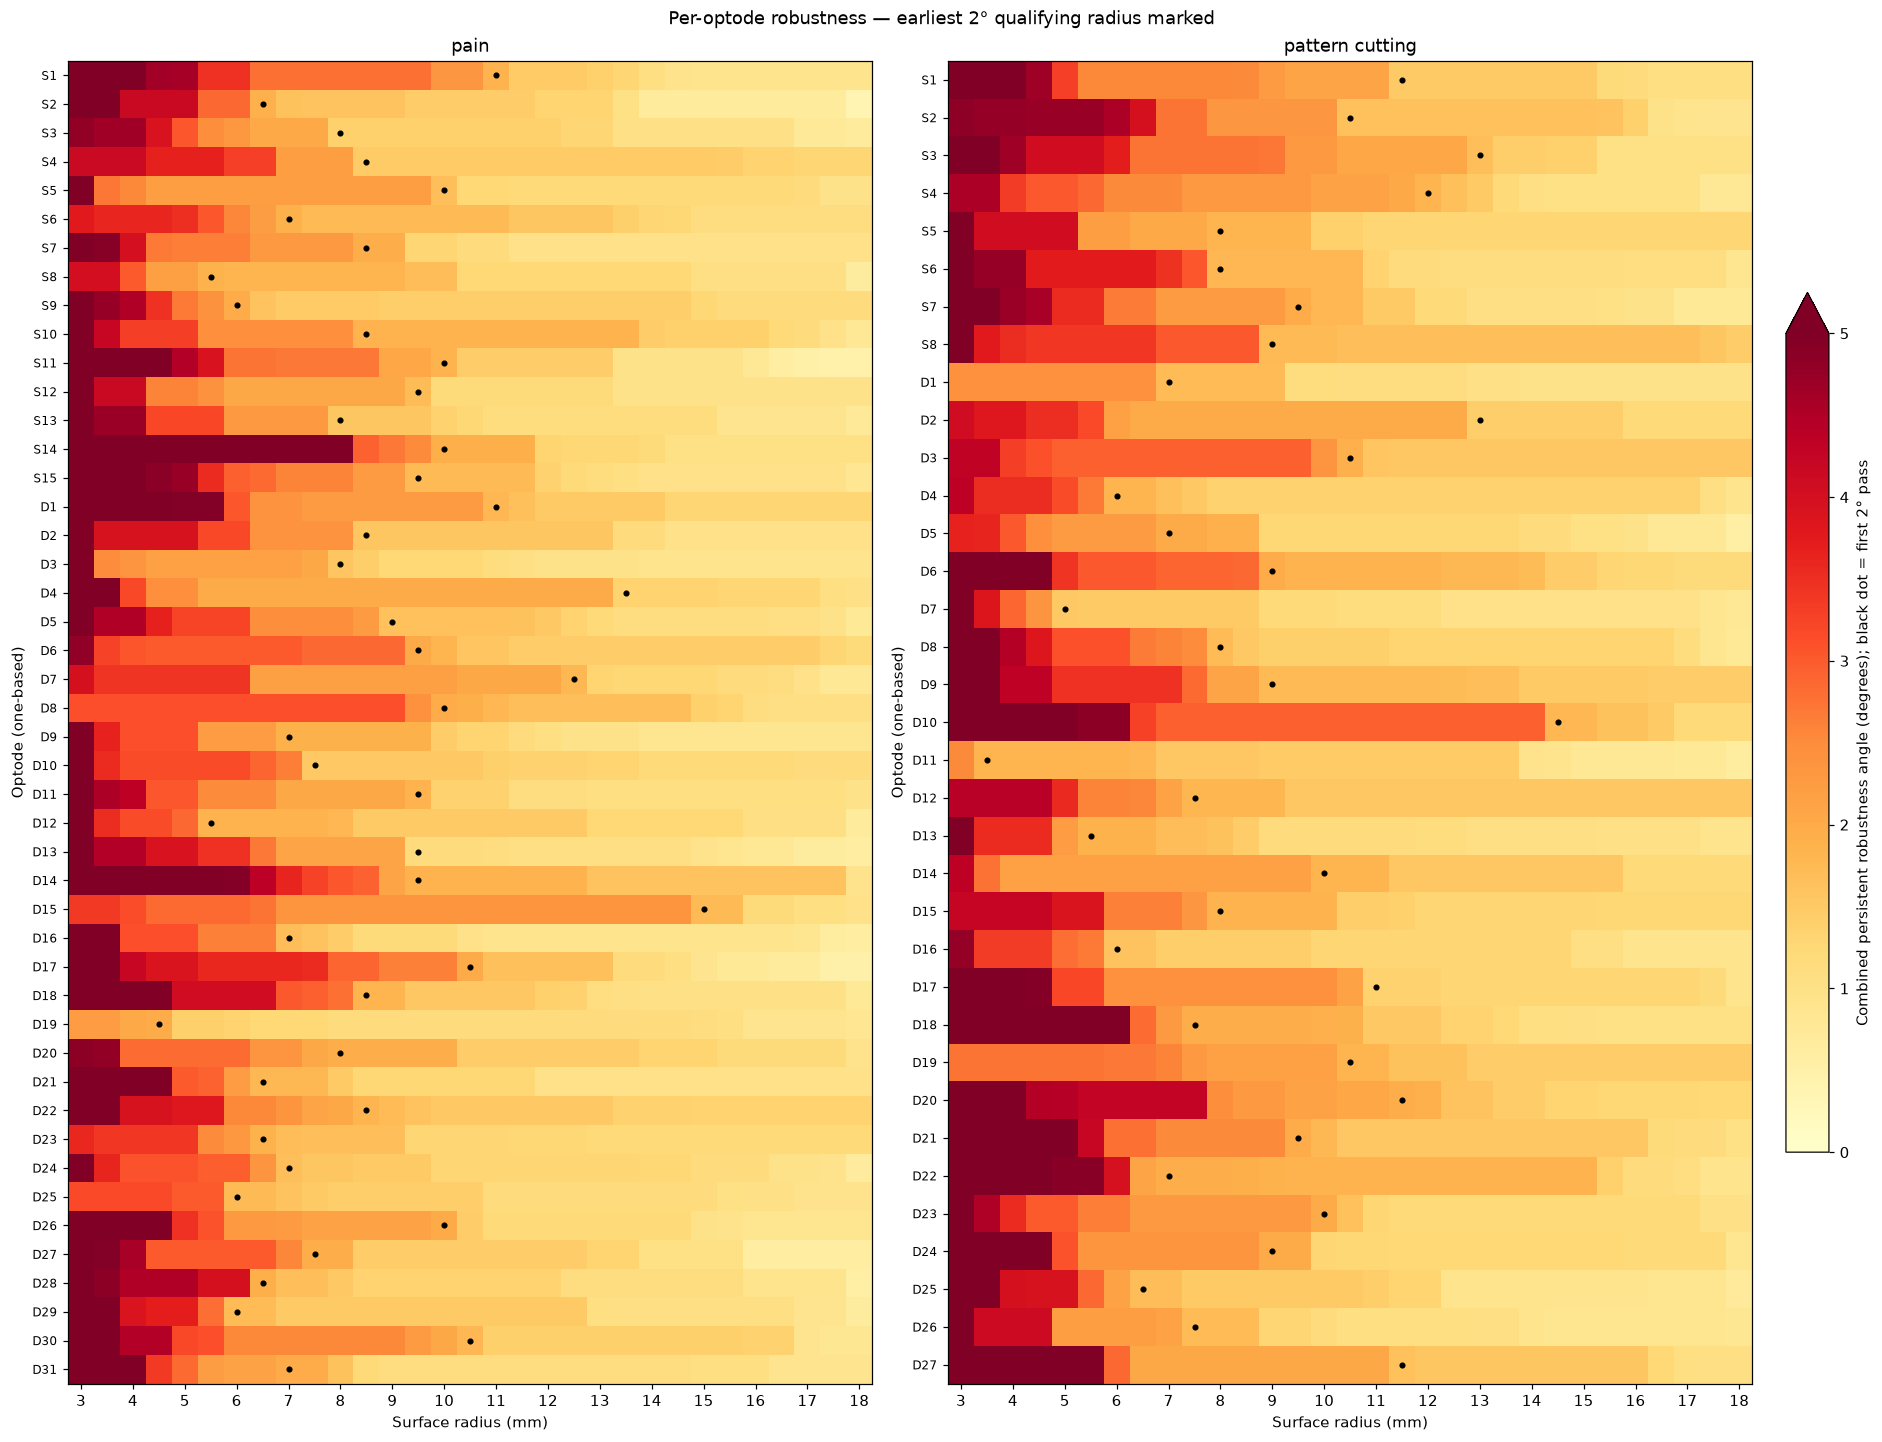

| dataset | optode | first_radius_1deg_mm | first_radius_2deg_mm | first_radius_3deg_mm | first_radius_5deg_mm |
|---|---|---|---|---|---|
| pain | S1 | 14.5 | 11 | 6.5 | 4.5 |
| pain | S2 | 14 | 6.5 | 5.5 | 4 |
| pain | S3 | not reached | 8 | 5.5 | 3 |
| pain | S4 | not reached | 8.5 | 7 | 3 |
| pain | S5 | not reached | 10 | 3.5 | 3.5 |
| pain | S6 | not reached | 7 | 6 | 3 |
| pain | S7 | 11.5 | 8.5 | 4.5 | 3.5 |
| pain | S8 | not reached | 5.5 | 4.5 | 3 |
| pain | S9 | not reached | 6 | 5 | 3.5 |
| pain | S10 | not reached | 8.5 | 5.5 | 3.5 |
| pain | S11 | 13.5 | 10 | 6 | 5 |
| pain | S12 | 13.5 | 9.5 | 4.5 | 3.5 |
| pain | S13 | 15.5 | 8 | 6 | 3.5 |
| pain | S14 | not reached | 10 | 8.5 | 8.5 |
| pain | S15 | 14 | 9.5 | 6 | 4.5 |
| pain | D1 | not reached | 11 | 6.5 | 3 |
| pain | D2 | 14.5 | 8.5 | 6.5 | 3.5 |
| pain | D3 | 12 | 8 | 3.5 | 3.5 |
| pain | D4 | not reached | 13.5 | 4.5 | 4 |
| pain | D5 | not reached | 9 | 6.5 | 3.5 |
| pain | D6 | not reached | 9.5 | 4.5 | 3 |
| pain | D7 | not reached | 12.5 | 6.5 | 3 |
| pain | D8 | not reached | 10 | 9.5 | 3 |
| pain | D9 | 12.5 | 7 | 5.5 | 3.5 |
| pain | D10 | not reached | 7.5 | 6.5 | 3.5 |
| pain | D11 | not reached | 9.5 | 5.5 | 3.5 |
| pain | D12 | not reached | 5.5 | 5 | 3.5 |
| pain | D13 | 15 | 9.5 | 6.5 | 3.5 |
| pain | D14 | not reached | 9.5 | 8.5 | 6 |
| pain | D15 | not reached | 15 | 4.5 | 3 |
| pain | D16 | 10.5 | 7 | 5.5 | 4 |
| pain | D17 | 15 | 10.5 | 8 | 4 |
| pain | D18 | 14 | 8.5 | 7.5 | 5 |
| pain | D19 | 16 | 4.5 | 3 | 3 |
| pain | D20 | not reached | 8 | 4 | 3 |
| pain | D21 | 12 | 6.5 | 5.5 | 5 |
| pain | D22 | not reached | 8.5 | 6 | 4 |
| pain | D23 | not reached | 6.5 | 5.5 | 3 |
| pain | D24 | not reached | 7 | 5.5 | 3.5 |
| pain | D25 | not reached | 6 | 6 | 3 |
| pain | D26 | 15 | 10 | 6 | 5 |
| pain | D27 | 16 | 7.5 | 7 | 3.5 |
| pain | D28 | 16 | 6.5 | 6.5 | 3.5 |
| pain | D29 | not reached | 6 | 5.5 | 4 |
| pain | D30 | not reached | 10.5 | 6 | 4 |
| pain | D31 | not reached | 7 | 5 | 4.5 |
| pattern cutting | S1 | not reached | 11.5 | 5.5 | 4.5 |
| pattern cutting | S2 | not reached | 10.5 | 7 | 3 |
| pattern cutting | S3 | not reached | 13 | 6.5 | 4 |
| pattern cutting | S4 | not reached | 12 | 5.5 | 3 |
| pattern cutting | S5 | not reached | 8 | 5.5 | 3.5 |
| pattern cutting | S6 | not reached | 8 | 8 | 3.5 |
| pattern cutting | S7 | 16 | 9.5 | 6 | 4 |
| pattern cutting | S8 | not reached | 9 | 9 | 3.5 |
| pattern cutting | D1 | 14 | 7 | 3 | 3 |
| pattern cutting | D2 | not reached | 13 | 6 | 3 |
| pattern cutting | D3 | not reached | 10.5 | 5 | 3 |
| pattern cutting | D4 | not reached | 6 | 5.5 | 3 |
| pattern cutting | D5 | 16 | 7 | 4.5 | 3 |
| pattern cutting | D6 | not reached | 9 | 7 | 5 |
| pattern cutting | D7 | 12.5 | 5 | 4 | 3.5 |
| pattern cutting | D8 | not reached | 8 | 6.5 | 4 |
| pattern cutting | D9 | not reached | 9 | 7.5 | 4 |
| pattern cutting | D10 | not reached | 14.5 | 7 | 5.5 |
| pattern cutting | D11 | 14 | 3.5 | 3 | 3 |
| pattern cutting | D12 | not reached | 7.5 | 5.5 | 3 |
| pattern cutting | D13 | not reached | 5.5 | 5 | 3.5 |
| pattern cutting | D14 | not reached | 10 | 3.5 | 3 |
| pattern cutting | D15 | not reached | 8 | 6 | 3 |
| pattern cutting | D16 | 16 | 6 | 5 | 3 |
| pattern cutting | D17 | not reached | 11 | 6 | 4.5 |
| pattern cutting | D18 | not reached | 7.5 | 6.5 | 6.5 |
| pattern cutting | D19 | not reached | 10.5 | 3 | 3 |
| pattern cutting | D20 | not reached | 11.5 | 8 | 4.5 |
| pattern cutting | D21 | not reached | 9.5 | 6 | 5.5 |
| pattern cutting | D22 | not reached | 7 | 6.5 | 5 |
| pattern cutting | D23 | not reached | 10 | 4.5 | 3.5 |
| pattern cutting | D24 | not reached | 9 | 5.5 | 5 |
| pattern cutting | D25 | 12.5 | 6.5 | 5.5 | 4 |
| pattern cutting | D26 | 14 | 7.5 | 5 | 3.5 |
| pattern cutting | D27 | not reached | 11.5 | 6 | 6 |

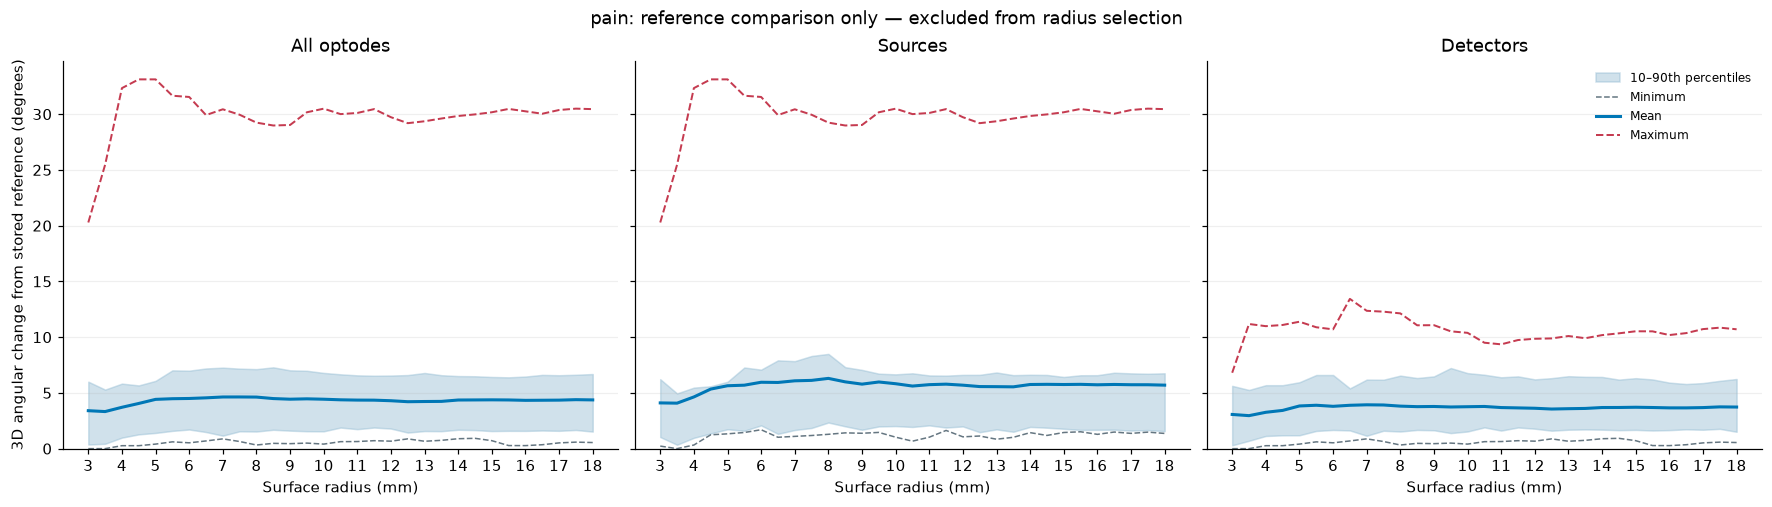

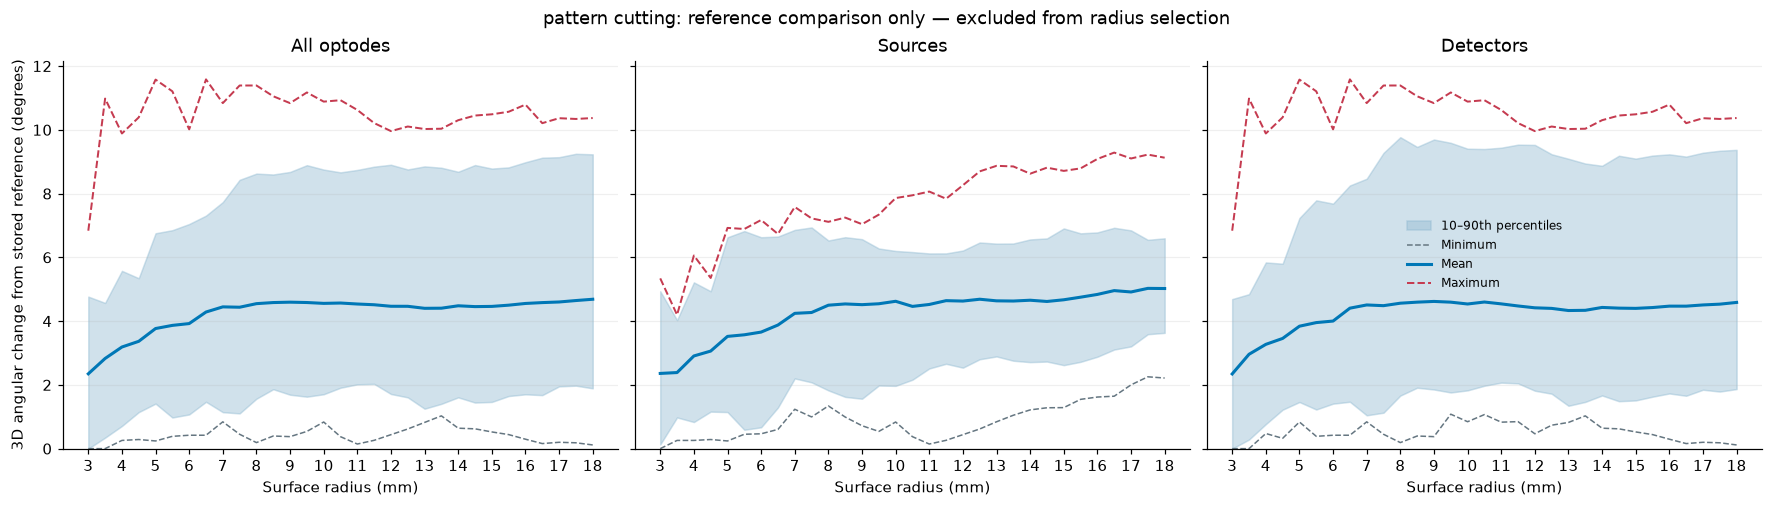

In [37]:
per_optode_robustness_rows=[]
fig,axes=plt.subplots(1,2,figsize=(17,13),layout="constrained")
for ax,(name,study) in zip(axes,radius_studies.items()):
    image=ax.imshow(study["score"],aspect="auto",interpolation="nearest",cmap="YlOrRd",
                    vmin=0,vmax=5,extent=(ROBUST_RADII_MM[0]-.25,ROBUST_RADII_MM[-1]+.25,
                                         len(study["labels"])-.5,-.5))
    ax.set_yticks(np.arange(len(study["labels"])),study["labels"])
    ax.set(title=name,xlabel="Surface radius (mm)",ylabel="Optode (one-based)",
           xticks=np.arange(3,19,1))
    for i,label in enumerate(study["labels"]):
        row=dict(dataset=name,optode=label)
        for tolerance in ROBUST_TOLERANCES_DEG:
            radius=earliest_radius(study,np.array([i]),tolerance,1.0)
            row[f"first_radius_{tolerance:g}deg_mm"]="not reached" if radius is None else f"{radius:g}"
        per_optode_robustness_rows.append(row)
        radius=earliest_radius(study,np.array([i]),WORKING_TOLERANCE_DEG,1.0)
        if radius is not None:
            ax.plot(radius,i,"o",color="black",ms=3)
    ax.tick_params(axis="y",labelsize=8)
fig.colorbar(image,ax=axes,shrink=.65,pad=.02,extend="max",
             label="Combined persistent robustness angle (degrees); black dot = first 2° pass")
fig.suptitle(f"Per-optode robustness — earliest {WORKING_TOLERANCE_DEG:g}° qualifying radius marked")
save_figure(fig,"per_optode_radius_robustness")
plt.show();plt.close(fig)
table(per_optode_robustness_rows)

for name,study in radius_studies.items():
    fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharey=True,layout="constrained")
    for ax,(group,ids) in zip(axes,study["groups"].items()):
        angular_summary_plot(ax,study["change_from_stored"][ids],group)
        # Reference agreement is not a tolerance criterion: omit that horizontal line here.
        ax.lines[-1].remove()
    axes[0].set_ylabel("3D angular change from stored reference (degrees)")
    axes[-1].legend(frameon=False,fontsize=8)
    fig.suptitle(name+": reference comparison only — excluded from radius selection")
    save_figure(fig,name.replace(" ","_")+"_dense_radius_reference_change")
    plt.show();plt.close(fig)


## 10. Candidate review and montage inspection
The table below reports the worst remaining perturbation sensitivity and radius drift at each probe's all-optode candidate, including the optodes that prevented the preceding 0.5 mm radius from passing. Separate 0.5/1 mm perturbation curves show how the chosen stress-test amplitude affects the result.

The montage panels are **inspection snapshots from the unified sweep**, not a second coarse experiment. Change `INSPECTION_RADII_MM` or `INSPECTION_CAMERA` below to inspect another subset/view. All source/detector arrows retain the same 30 mm display scale.

| dataset | candidate_mm | worst_persistent_1mm_deg | worst_radius_drift_deg | previous_radius_blockers |
|---|---|---|---|---|
| pain | 15 | 1.757 | 1.026 | D15 |
| pattern cutting | 14.5 | 1.840 | 1.627 | D10 |

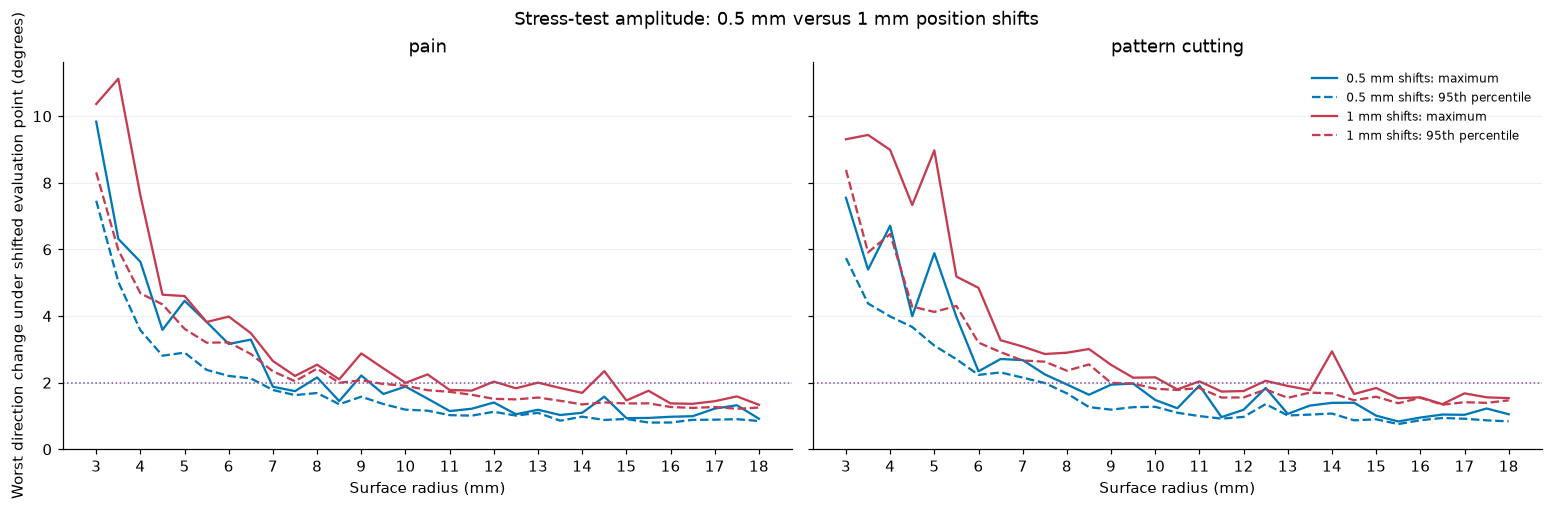

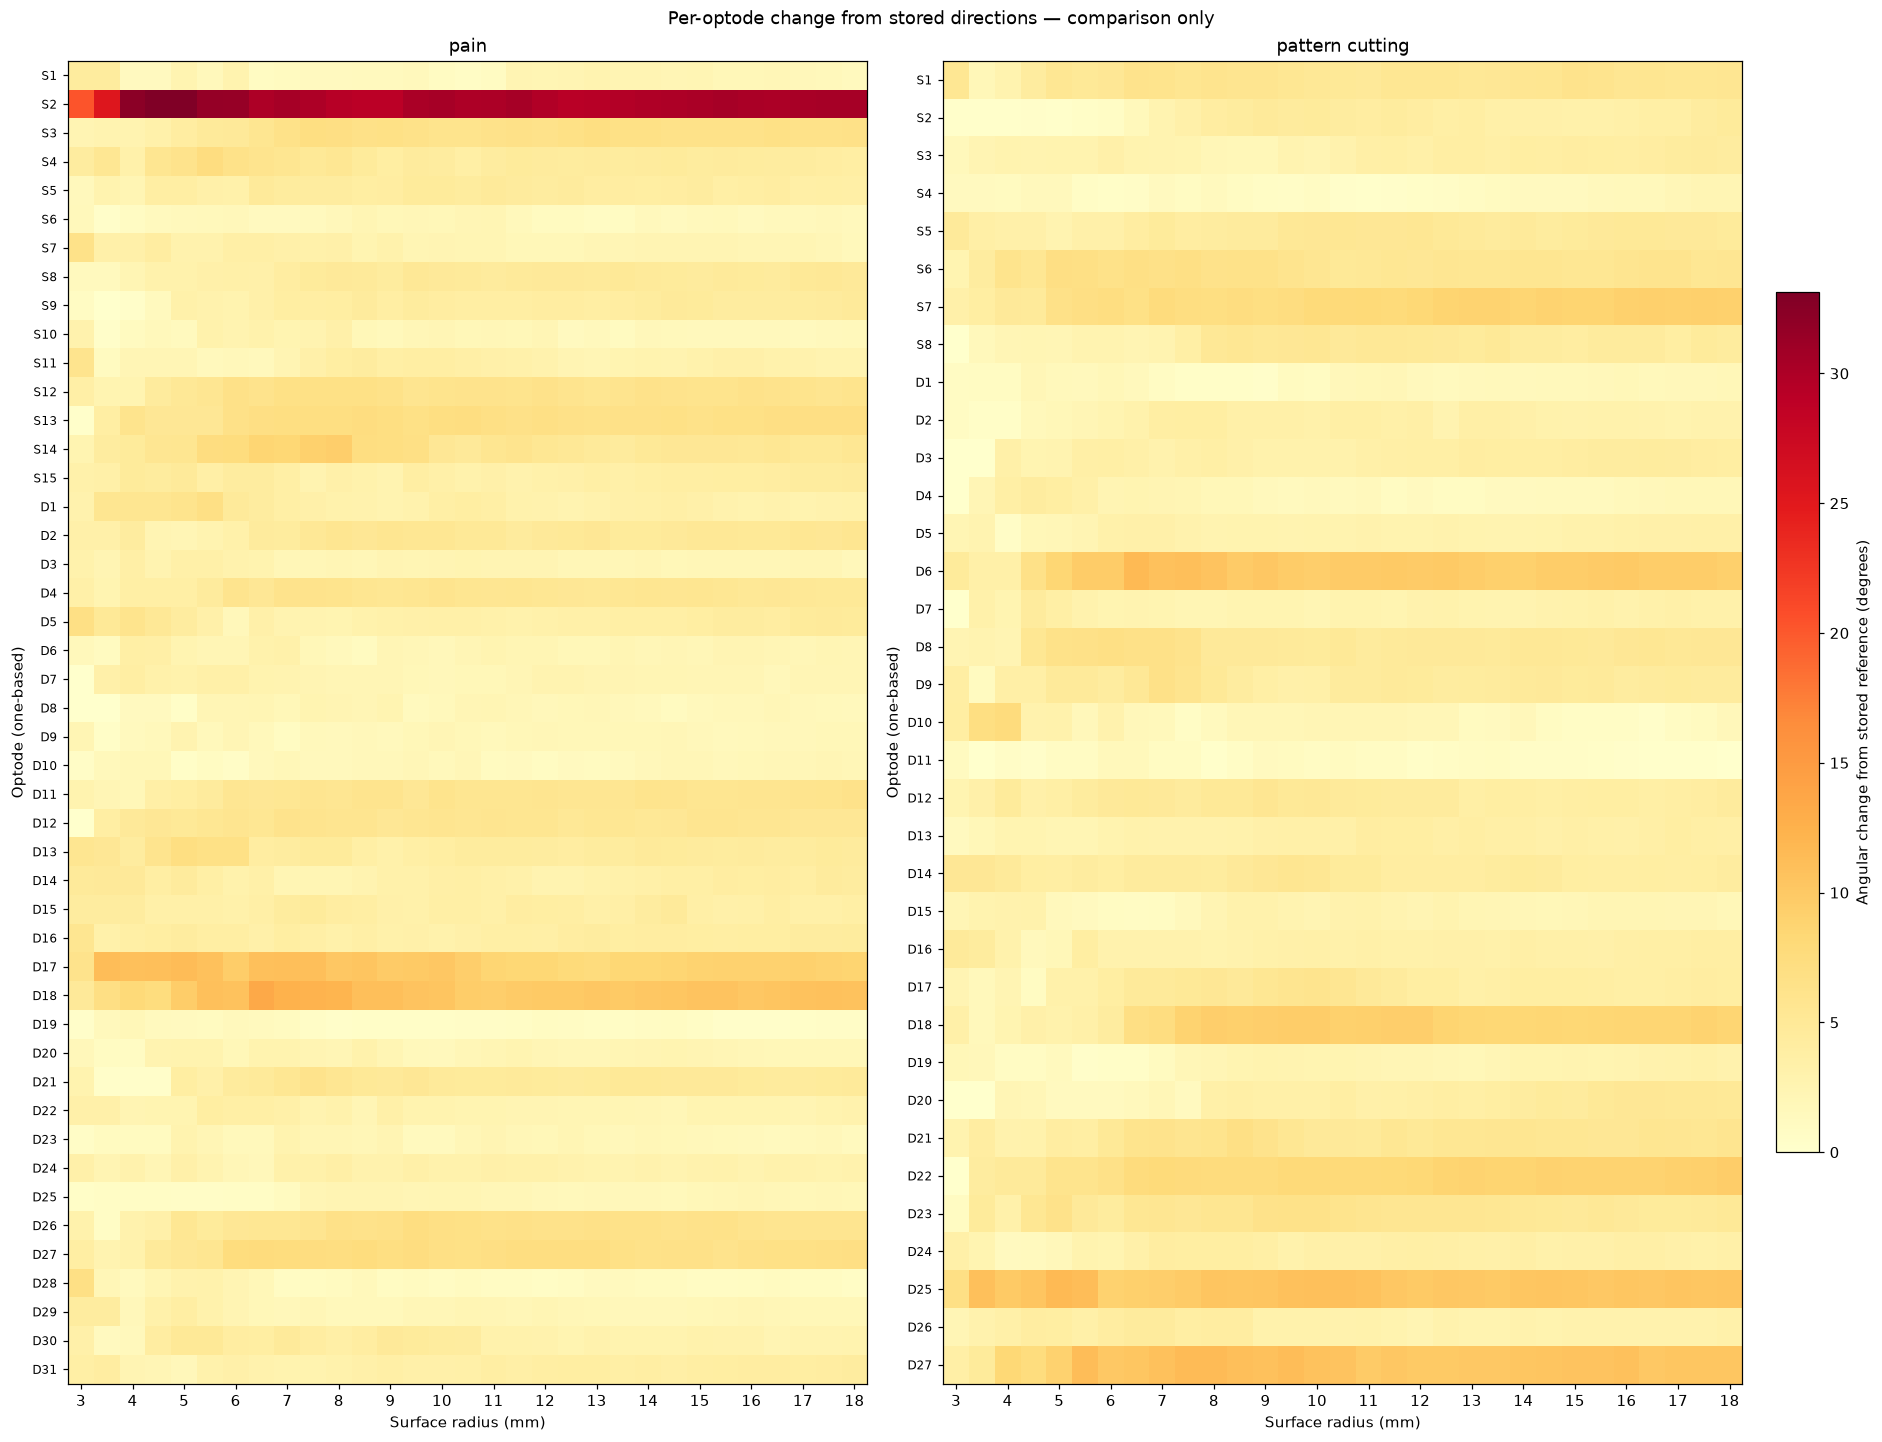

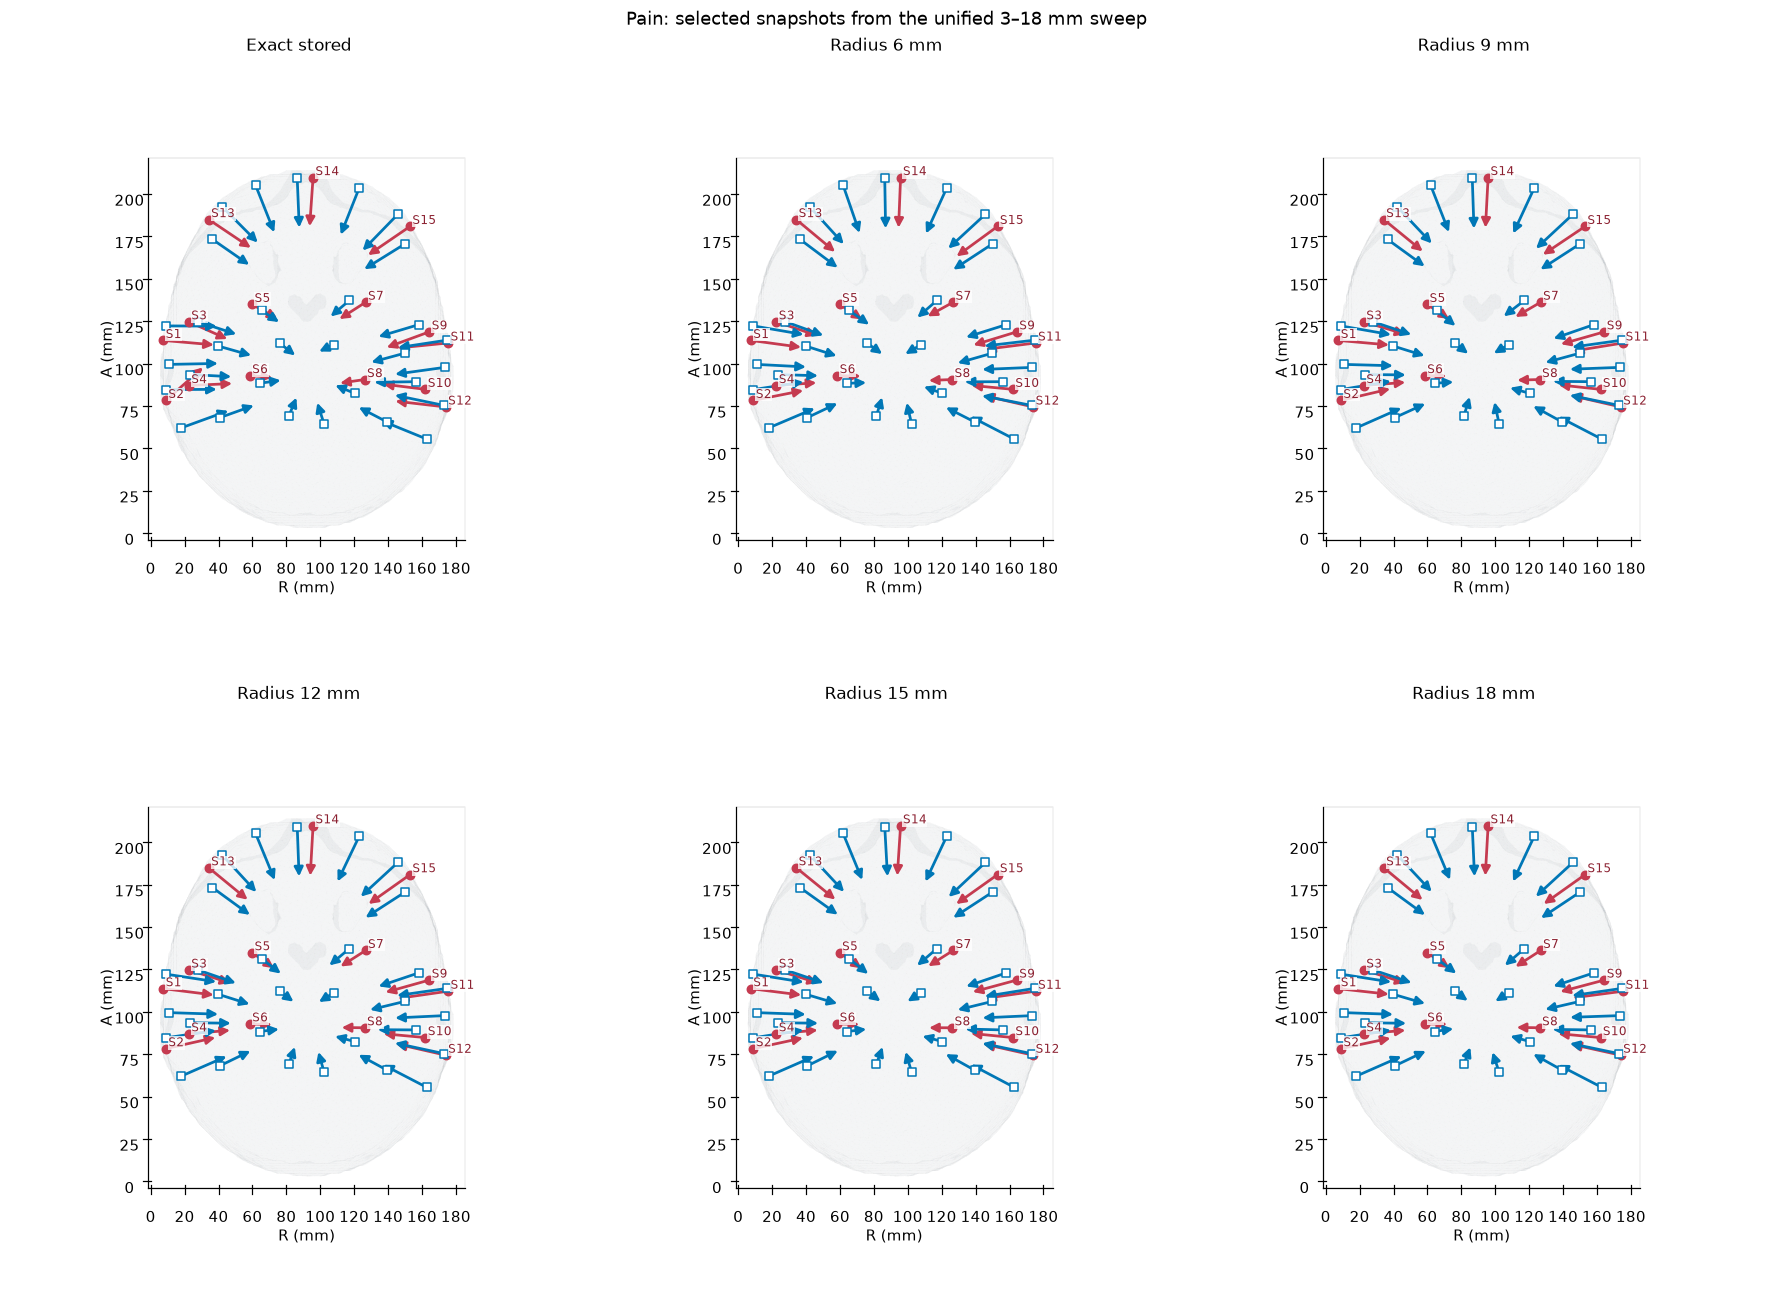

All audited inputs unchanged. Production direction rule unchanged.
Per-optode reference-angle data: per_optode_radius_angles.


In [38]:
candidate_review_rows=[]
for name,study in radius_studies.items():
    radius=working_candidates[name]
    if radius is None:
        candidate_review_rows.append(dict(dataset=name,candidate_mm="not reached",
            worst_persistent_1mm_deg="—",worst_radius_drift_deg="—",previous_radius_blockers="—"))
        continue
    j=int(np.flatnonzero(np.isclose(ROBUST_RADII_MM,radius))[0])
    previous=max(j-1,0)
    blockers=np.flatnonzero((study["score"][:,previous]>WORKING_TOLERANCE_DEG)
                            |(~study["persistent_geometry"][:,previous]))
    candidate_review_rows.append(dict(dataset=name,candidate_mm=f"{radius:g}",
        worst_persistent_1mm_deg=f"{study['persistent_jitter'][:,j].max():.3f}",
        worst_radius_drift_deg=f"{study['tail_diameter'][:,j].max():.3f}",
        previous_radius_blockers=", ".join(study["labels"][i] for i in blockers)))
table(candidate_review_rows)

fig,axes=plt.subplots(1,2,figsize=(14,4.5),sharey=True,layout="constrained")
for ax,(name,study) in zip(axes,radius_studies.items()):
    for amplitude,color in ((.5,"#0077b6"),(1.0,"#c53b50")):
        values=study["jitter"][amplitude]
        ax.plot(ROBUST_RADII_MM,values.max(0),color=color,lw=1.5,label=f"{amplitude:g} mm shifts: maximum")
        ax.plot(ROBUST_RADII_MM,np.quantile(values,.95,axis=0),color=color,ls="--",lw=1.5,
                label=f"{amplitude:g} mm shifts: 95th percentile")
    ax.axhline(WORKING_TOLERANCE_DEG,color="#8053a0",lw=1,ls=":")
    ax.set(title=name,xlabel="Surface radius (mm)",ylim=(0,None),xticks=np.arange(3,19,1))
    ax.grid(axis="y",alpha=.2);ax.spines[["top","right"]].set_visible(False)
axes[0].set_ylabel("Worst direction change under shifted evaluation point (degrees)")
axes[-1].legend(frameon=False,fontsize=8)
fig.suptitle("Stress-test amplitude: 0.5 mm versus 1 mm position shifts")
save_figure(fig,"radius_perturbation_amplitude_comparison")
plt.show();plt.close(fig)

# Preserve per-optode reference changes for detailed numeric review.
per_optode_radius_angles={
    name:[dict(optode=label,**{f"{radius:g}_mm_deg":float(study["change_from_stored"][i,j])
                              for j,radius in enumerate(ROBUST_RADII_MM)})
          for i,label in enumerate(study["labels"])]
    for name,study in radius_studies.items()
}
fig,axes=plt.subplots(1,2,figsize=(17,13),layout="constrained")
reference_vmax=max(study["change_from_stored"].max() for study in radius_studies.values())
for ax,(name,study) in zip(axes,radius_studies.items()):
    image=ax.imshow(study["change_from_stored"],aspect="auto",interpolation="nearest",cmap="YlOrRd",
                    vmin=0,vmax=reference_vmax,extent=(2.75,18.25,len(study["labels"])-.5,-.5))
    ax.set_yticks(np.arange(len(study["labels"])),study["labels"])
    ax.set(title=name,xlabel="Surface radius (mm)",ylabel="Optode (one-based)",xticks=np.arange(3,19,1))
    ax.tick_params(axis="y",labelsize=8)
fig.colorbar(image,ax=axes,shrink=.65,pad=.02,label="Angular change from stored reference (degrees)")
fig.suptitle("Per-optode change from stored directions — comparison only")
save_figure(fig,"per_optode_dense_radius_reference_changes")
plt.show();plt.close(fig)

INSPECTION_RADII_MM=(6.0,9.0,12.0,15.0,18.0)
INSPECTION_CAMERA="superior"
study=radius_studies["pain"]
inspection=[("Exact stored",study["probe"])]
ns=len(study["probe"]["sourcepos"])
for radius in INSPECTION_RADII_MM:
    j=int(np.flatnonzero(np.isclose(ROBUST_RADII_MM,radius))[0])
    vectors=study["vectors"][j]
    inspection.append((f"Radius {radius:g} mm",dict(study["probe"],sourcedir=vectors[:ns],detnorms=vectors[ns:])))
fig=plt.figure(figsize=(16,12),layout="constrained")
for panel,(label,probe) in enumerate(inspection):
    ax=fig.add_subplot(2,3,panel+1,projection="3d",computed_zorder=False)
    draw_registration(ax,pain_data["nodes"],pain_data["surface"],probe,label,INSPECTION_CAMERA)
    for i,point in enumerate(probe["sourcepos"]):
        ax.text(*(point+np.array([1.4,1.4,1.4])),f"S{i+1}",fontsize=8,color="#8b2030",zorder=20,
                bbox=dict(facecolor="white",edgecolor="none",alpha=.8,pad=.3))
fig.suptitle("Pain: selected snapshots from the unified 3–18 mm sweep")
save_figure(fig,"pain_unified_radius_inspection")
plt.show();plt.close(fig)

assert all(sha256(Path(r["path"]) if Path(r["path"]).is_absolute() else ROOT/r["path"])==r["sha256"]
           for r in provenance)
print("All audited inputs unchanged. Production direction rule unchanged.")
print("Per-optode reference-angle data: per_optode_radius_angles.")
